# Dataset B — Research EDA

Notebook này tạo dữ liệu nền và hình mô tả phục vụ research cho 12 raw features thuộc `temporary_training_lock_v0_2`. Notebook không thay thế feature-selection evidence trong `04_feature_selection.ipynb` và không tạo quyết định `keep`/`exclude`.

## Task 01 — Scope, provenance, and full-cohort EDA view

Phạm vi Task 01:

- đọc trực tiếp raw HMDA New York 2024;
- giữ cohort có `action_taken ∈ {1, 2, 3}`;
- lấy đúng 12 raw features từ feature contract hiện hành;
- không tạo `y_approved` vì Task 01 chưa phân tích target;
- không đọc Train/Validation/Test hoặc ma trận preprocessing 66 cột;
- không impute, encode, scale, clip, winsorize hoặc biến đổi raw values;
- không execute hoặc phụ thuộc vào kernel state của `04_feature_selection.ipynb`.


### 1. Thiết lập project và nguồn dữ liệu

Cell này xác định project root từ contract Dataset B thay vì phụ thuộc vào thư mục mở notebook.


In [1]:
import sys
from pathlib import Path

import pandas as pd
import yaml

PROJECT_ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (
        path
        / "config"
        / "dataset_b"
        / "feature_set_v1.yaml"
    ).exists()
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.path import CONFIG_DIR, RAW_STATE_NY_PATH

FEATURE_CONTRACT_PATH = (
    CONFIG_DIR / "dataset_b" / "feature_set_v1.yaml"
)


### 2. Đọc feature contract hiện hành

Danh sách feature được đọc từ config nguồn chuẩn, không sao chép từ notebook model hoặc từ config legacy.


In [2]:
with FEATURE_CONTRACT_PATH.open(
    encoding="utf-8"
) as handle:
    eda_feature_contract = yaml.safe_load(handle)

assert eda_feature_contract["dataset"] == "dataset_b"

eda_target_contract = eda_feature_contract["target"]
EDA_TARGET_SOURCE = eda_target_contract["source_column"]
EDA_ELIGIBLE_ACTIONS = frozenset(
    str(value)
    for value in eda_target_contract["eligible_values"]
)
EDA_FEATURES = tuple(
    eda_feature_contract["model_input_raw_columns"]
)
EDA_AUDIT_COLUMNS = tuple(
    eda_feature_contract["audit_only_columns"]
)

assert EDA_TARGET_SOURCE == "action_taken"
assert EDA_ELIGIBLE_ACTIONS == {"1", "2", "3"}
assert len(EDA_FEATURES) == 12
assert len(set(EDA_FEATURES)) == len(EDA_FEATURES)
assert EDA_TARGET_SOURCE not in EDA_FEATURES
assert set(EDA_FEATURES).isdisjoint(EDA_AUDIT_COLUMNS)

pd.Series(
    {
        "dataset": eda_feature_contract["dataset"],
        "feature_version": eda_feature_contract[
            "feature_version"
        ],
        "feature_count": len(EDA_FEATURES),
        "target_source": EDA_TARGET_SOURCE,
        "eligible_actions": sorted(
            EDA_ELIGIBLE_ACTIONS
        ),
    },
    name="Task 01 contract",
)


dataset                                dataset_b
feature_version     temporary_training_lock_v0_2
feature_count                                 12
target_source                       action_taken
eligible_actions                       [1, 2, 3]
Name: Task 01 contract, dtype: object

### 3. Đọc immutable raw source

Mọi cột được đọc dưới dạng string và pandas không tự chuyển literal `NA` thành missing. Raw frame chỉ được đọc và kiểm tra; các bước sau tạo bản sao riêng.


In [3]:
eda_raw_source = pd.read_csv(
    RAW_STATE_NY_PATH,
    dtype="string",
    keep_default_na=False,
)

eda_raw_shape_at_load = eda_raw_source.shape
eda_raw_columns_at_load = tuple(eda_raw_source.columns)

assert eda_raw_source.shape[1] == 99
assert eda_raw_source.columns.is_unique

eda_required_raw_columns = {
    EDA_TARGET_SOURCE,
    *EDA_FEATURES,
}
eda_missing_raw_columns = sorted(
    eda_required_raw_columns
    - set(eda_raw_source.columns)
)
assert not eda_missing_raw_columns, (
    f"Missing raw columns: {eda_missing_raw_columns}"
)


### 4. Tạo full-cohort EDA view

Cohort chỉ dùng `action_taken` để xác định population. Figure frame chỉ chứa 12 predictors; target source và audit metadata không đi vào dữ liệu dùng cho hình.


In [4]:
eda_eligible_mask = eda_raw_source[
    EDA_TARGET_SOURCE
].isin(EDA_ELIGIBLE_ACTIONS)

eda_raw_cohort = eda_raw_source.loc[
    eda_eligible_mask,
    [EDA_TARGET_SOURCE, *EDA_FEATURES],
].copy()

eda_feature_frame = eda_raw_cohort.loc[
    :,
    list(EDA_FEATURES),
].copy()


### 5. Task 01 acceptance gate

Các assertion dưới đây chỉ xác nhận population, feature boundary và tính bất biến cấu trúc của raw frame. Chúng không lặp lại quality/decision tables của feature-selection notebook.


In [5]:
EXPECTED_DATASET_B_ROWS = 293_301

eda_forbidden_figure_columns = {
    "record_id",
    EDA_TARGET_SOURCE,
    eda_target_contract["name"],
    *EDA_AUDIT_COLUMNS,
}

assert len(eda_raw_cohort) == EXPECTED_DATASET_B_ROWS
assert eda_feature_frame.shape == (
    EXPECTED_DATASET_B_ROWS,
    len(EDA_FEATURES),
)
assert tuple(eda_feature_frame.columns) == EDA_FEATURES
assert eda_forbidden_figure_columns.isdisjoint(
    eda_feature_frame.columns
)
assert set(eda_raw_cohort[EDA_TARGET_SOURCE].unique()) == (
    EDA_ELIGIBLE_ACTIONS
)
assert eda_raw_source.shape == eda_raw_shape_at_load
assert tuple(eda_raw_source.columns) == (
    eda_raw_columns_at_load
)

eda_task_01_summary = pd.Series(
    {
        "raw_source": str(RAW_STATE_NY_PATH),
        "raw_rows": len(eda_raw_source),
        "raw_columns": eda_raw_source.shape[1],
        "dataset_b_rows": len(eda_raw_cohort),
        "excluded_rows": int(
            (~eda_eligible_mask).sum()
        ),
        "figure_feature_count": (
            eda_feature_frame.shape[1]
        ),
        "feature_version": eda_feature_contract[
            "feature_version"
        ],
        "target_created": False,
        "split_artifact_used": False,
        "model_preprocessing_used": False,
    },
    name="Task 01 acceptance summary",
)

eda_task_01_summary


raw_source                  D:\FPTU_Study\FA2026\DAP391m_GR12\data\raw\sta...
raw_rows                                                               383614
raw_columns                                                                99
dataset_b_rows                                                         293301
excluded_rows                                                           90313
figure_feature_count                                                       12
feature_version                                  temporary_training_lock_v0_2
target_created                                                          False
split_artifact_used                                                     False
model_preprocessing_used                                                False
Name: Task 01 acceptance summary, dtype: object

## Task 01 stop point

Task 01 kết thúc sau khi acceptance gate PASS. Notebook chưa parse numeric features, chưa tính association, chưa tạo figure, chưa phân tích target/protected groups và chưa ghi bất kỳ artifact nào. Các bước đó chỉ được thêm trong task tiếp theo sau khi Task 01 được chạy và review.


## Task 02 — Build plot-ready data views

Task 02 chỉ phân loại 12 raw features thành numeric/categorical views và kiểm tra tính toàn vẹn trước khi vẽ. Đây không phải feature selection mới: không tạo target, không dùng split/model preprocessing, không clip hoặc impute dữ liệu, và chưa tạo figure. Các mốc đếm đã lưu trong `04_feature_selection.ipynb` chỉ được dùng làm reference assertions để phát hiện sai lệch.


In [6]:
import numpy as np

eda_task_01_required = {
    "eda_feature_frame",
    "eda_raw_cohort",
    "EDA_FEATURES",
    "EDA_AUDIT_COLUMNS",
    "EDA_TARGET_SOURCE",
    "EXPECTED_DATASET_B_ROWS",
    "eda_forbidden_figure_columns",
}
eda_task_01_missing = sorted(
    name
    for name in eda_task_01_required
    if name not in globals()
)
assert not eda_task_01_missing, (
    "Run Task 01 first. Missing variables: "
    f"{eda_task_01_missing}"
)

EDA_NUMERIC_FEATURES = (
    "income",
    "loan_amount",
    "loan_to_value_ratio",
    "loan_term",
)
EDA_CATEGORICAL_FEATURES = (
    "loan_type",
    "loan_purpose",
    "lien_status",
    "reverse_mortgage",
    "open-end_line_of_credit",
    "business_or_commercial_purpose",
    "debt_to_income_ratio",
    "occupancy_type",
)
EDA_NUMERIC_SPECIAL_TOKENS = {
    "income": frozenset({"NA"}),
    "loan_amount": frozenset(),
    "loan_to_value_ratio": frozenset(
        {"NA", "Exempt"}
    ),
    "loan_term": frozenset({"NA", "Exempt"}),
}
EDA_CATEGORICAL_DOMAINS = {
    "loan_type": frozenset({"1", "2", "3", "4"}),
    "loan_purpose": frozenset(
        {"1", "2", "31", "32", "4", "5"}
    ),
    "lien_status": frozenset({"1", "2"}),
    "reverse_mortgage": frozenset(
        {"1", "2", "1111"}
    ),
    "open-end_line_of_credit": frozenset(
        {"1", "2", "1111"}
    ),
    "business_or_commercial_purpose": frozenset(
        {"1", "2", "1111"}
    ),
    "debt_to_income_ratio": frozenset(
        {
            "<20%",
            "20%-<30%",
            "30%-<36%",
            "50%-60%",
            ">60%",
            "NA",
            "Exempt",
            *(str(value) for value in range(36, 50)),
        }
    ),
    "occupancy_type": frozenset({"1", "2", "3"}),
}
EDA_CATEGORICAL_SPECIAL_TOKENS = {
    "loan_type": frozenset(),
    "loan_purpose": frozenset(),
    "lien_status": frozenset(),
    "reverse_mortgage": frozenset({"1111"}),
    "open-end_line_of_credit": frozenset({"1111"}),
    "business_or_commercial_purpose": frozenset(
        {"1111"}
    ),
    "debt_to_income_ratio": frozenset(
        {"NA", "Exempt"}
    ),
    "occupancy_type": frozenset(),
}

assert len(EDA_NUMERIC_FEATURES) == 4
assert len(EDA_CATEGORICAL_FEATURES) == 8
assert set(EDA_NUMERIC_FEATURES).isdisjoint(
    EDA_CATEGORICAL_FEATURES
)
assert set(EDA_NUMERIC_FEATURES) | set(
    EDA_CATEGORICAL_FEATURES
) == set(EDA_FEATURES)
assert tuple(EDA_NUMERIC_SPECIAL_TOKENS) == (
    EDA_NUMERIC_FEATURES
)
assert tuple(EDA_CATEGORICAL_DOMAINS) == (
    EDA_CATEGORICAL_FEATURES
)

print("[PASS] Task 01 variables are available.")
print("[PASS] Feature roles reconcile: 4 numeric + 8 categorical = 12.")
print("[PASS] DTI remains categorical; raw special states remain explicit.")


[PASS] Task 01 variables are available.
[PASS] Feature roles reconcile: 4 numeric + 8 categorical = 12.
[PASS] DTI remains categorical; raw special states remain explicit.


### 6. Numeric plot view and token-status audit

Numeric values được parse sang `float64` trong một view mới. `NA`/`Exempt` trở thành `NaN` trong numeric view nhưng vẫn được giữ riêng trong status view; raw frame không thay đổi. Income âm/0 và các giá trị đuôi dài vẫn được bảo toàn để các hình sau phản ánh đúng dữ liệu raw.


In [7]:
eda_numeric_view = pd.DataFrame(
    index=eda_feature_frame.index
)
eda_numeric_status_view = pd.DataFrame(
    index=eda_feature_frame.index
)
eda_numeric_quality_rows = []

for feature in EDA_NUMERIC_FEATURES:
    raw_values = eda_feature_frame[feature]
    normalized = raw_values.astype("string").str.strip()
    missing_mask = (
        raw_values.isna()
        | normalized.eq("").fillna(False)
    )
    whitespace_changed_mask = (
        ~missing_mask
        & raw_values.astype("string")
        .ne(normalized)
        .fillna(False)
    )
    special_tokens = EDA_NUMERIC_SPECIAL_TOKENS[feature]
    special_mask = normalized.isin(special_tokens)
    parsed = pd.to_numeric(
        normalized.mask(missing_mask | special_mask),
        errors="coerce",
    ).astype("float64")
    nonfinite_mask = (
        parsed.notna() & ~np.isfinite(parsed)
    )
    invalid_mask = (
        ~missing_mask
        & ~special_mask
        & (parsed.isna() | nonfinite_mask)
    )
    parsed = parsed.mask(nonfinite_mask)

    status = pd.Series(
        "INVALID",
        index=raw_values.index,
        dtype="string",
    )
    status.loc[missing_mask] = "MISSING"
    for token in sorted(special_tokens):
        status.loc[normalized.eq(token)] = token
    status.loc[parsed.notna()] = "OBSERVED"

    eda_numeric_view[feature] = parsed
    eda_numeric_status_view[feature] = status
    eda_numeric_quality_rows.append(
        {
            "feature": feature,
            "row_count": len(raw_values),
            "numeric_n": int(parsed.notna().sum()),
            "special_n": int(special_mask.sum()),
            "NA_n": int(normalized.eq("NA").sum()),
            "Exempt_n": int(
                normalized.eq("Exempt").sum()
            ),
            "missing_n": int(missing_mask.sum()),
            "invalid_n": int(invalid_mask.sum()),
            "whitespace_changed_n": int(
                whitespace_changed_mask.sum()
            ),
            "negative_n": int(parsed.lt(0).sum()),
            "zero_n": int(parsed.eq(0).sum()),
            "positive_n": int(parsed.gt(0).sum()),
            "raw_unique_count": int(
                raw_values.nunique(dropna=False)
            ),
        }
    )

eda_task_02_numeric_quality = pd.DataFrame(
    eda_numeric_quality_rows
)


In [8]:
EDA_NUMERIC_REFERENCE_FROM_04 = {
    "income": {
        "numeric_n": 272_723,
        "NA_n": 20_578,
        "Exempt_n": 0,
    },
    "loan_amount": {
        "numeric_n": 293_301,
        "NA_n": 0,
        "Exempt_n": 0,
    },
    "loan_to_value_ratio": {
        "numeric_n": 274_681,
        "NA_n": 9_978,
        "Exempt_n": 8_642,
    },
    "loan_term": {
        "numeric_n": 274_648,
        "NA_n": 10_360,
        "Exempt_n": 8_293,
    },
}

numeric_quality_by_feature = (
    eda_task_02_numeric_quality
    .set_index("feature")
)
for feature, expected in (
    EDA_NUMERIC_REFERENCE_FROM_04.items()
):
    observed = numeric_quality_by_feature.loc[feature]
    assert observed["row_count"] == EXPECTED_DATASET_B_ROWS
    assert observed["missing_n"] == 0
    assert observed["invalid_n"] == 0
    assert observed["whitespace_changed_n"] == 0
    assert (
        observed["numeric_n"]
        + observed["special_n"]
        + observed["missing_n"]
        + observed["invalid_n"]
        == EXPECTED_DATASET_B_ROWS
    )
    for metric, expected_value in expected.items():
        assert observed[metric] == expected_value, (
            f"{feature}.{metric}: "
            f"observed={observed[metric]}, "
            f"expected={expected_value}"
        )

assert int(eda_numeric_view["income"].lt(0).sum()) == 360
assert int(eda_numeric_view["income"].eq(0).sum()) == 3_111
assert int(
    eda_numeric_view["loan_to_value_ratio"].gt(1_000).sum()
) == 60
for feature in (
    "loan_amount",
    "loan_to_value_ratio",
    "loan_term",
):
    assert eda_numeric_view[feature].dropna().gt(0).all()
assert (
    eda_numeric_view["loan_term"].dropna().mod(1).eq(0).all()
)

print("[DATA QUALITY] Numeric plot view")
print(eda_task_02_numeric_quality.to_string(index=False))
print("[PASS] No blank, invalid, non-finite, or whitespace-altered numeric tokens.")
print("[PASS] Numeric/special counts match saved 04_feature_selection evidence.")
print("[PASS] Raw income negatives/zeros and extreme LTV values remain available for EDA.")


[DATA QUALITY] Numeric plot view
            feature  row_count  numeric_n  special_n  NA_n  Exempt_n  missing_n  invalid_n  whitespace_changed_n  negative_n  zero_n  positive_n  raw_unique_count
             income     293301     272723      20578 20578         0          0          0                     0         360    3111      269252              3007
        loan_amount     293301     293301          0     0         0          0          0                     0           0       0      293301               993
loan_to_value_ratio     293301     274681      18620  9978      8642          0          0                     0           0       0      274681             80236
          loan_term     293301     274648      18653 10360      8293          0          0                     0           0       0      274648               338
[PASS] No blank, invalid, non-finite, or whitespace-altered numeric tokens.
[PASS] Numeric/special counts match saved 04_feature_selection evidence.
[PA

### 7. Categorical plot view and domain audit

Categorical view giữ nguyên raw tokens để dùng cho count/share plots sau này. Domain checks chỉ phân biệt informative, special, missing và invalid; không encode hoặc gộp category.


In [9]:
eda_categorical_view = eda_feature_frame.loc[
    :,
    list(EDA_CATEGORICAL_FEATURES),
].copy()
eda_categorical_quality_rows = []

for feature in EDA_CATEGORICAL_FEATURES:
    raw_values = eda_categorical_view[feature]
    normalized = raw_values.astype("string").str.strip()
    missing_mask = (
        raw_values.isna()
        | normalized.eq("").fillna(False)
    )
    whitespace_changed_mask = (
        ~missing_mask
        & raw_values.astype("string")
        .ne(normalized)
        .fillna(False)
    )
    domain = EDA_CATEGORICAL_DOMAINS[feature]
    special_tokens = EDA_CATEGORICAL_SPECIAL_TOKENS[feature]
    valid_mask = normalized.isin(domain)
    special_mask = normalized.isin(special_tokens)
    invalid_mask = ~missing_mask & ~valid_mask
    informative_mask = valid_mask & ~special_mask

    eda_categorical_quality_rows.append(
        {
            "feature": feature,
            "row_count": len(raw_values),
            "valid_n": int(valid_mask.sum()),
            "informative_n": int(
                informative_mask.sum()
            ),
            "special_n": int(special_mask.sum()),
            "missing_n": int(missing_mask.sum()),
            "invalid_n": int(invalid_mask.sum()),
            "whitespace_changed_n": int(
                whitespace_changed_mask.sum()
            ),
            "raw_unique_count": int(
                raw_values.nunique(dropna=False)
            ),
        }
    )

eda_task_02_categorical_quality = pd.DataFrame(
    eda_categorical_quality_rows
)

for row in eda_task_02_categorical_quality.itertuples(
    index=False
):
    assert row.row_count == EXPECTED_DATASET_B_ROWS
    assert row.missing_n == 0
    assert row.invalid_n == 0
    assert row.whitespace_changed_n == 0
    assert row.valid_n == row.informative_n + row.special_n
    assert (
        row.valid_n + row.missing_n + row.invalid_n
        == EXPECTED_DATASET_B_ROWS
    )

print("[DATA QUALITY] Categorical plot view")
print(eda_task_02_categorical_quality.to_string(index=False))
print("[PASS] All categorical tokens are inside the agreed raw domains.")
print("[PASS] No blank, invalid, or whitespace-altered categorical tokens.")
print("[PASS] Special categories remain explicit; no encoding or grouping was applied.")


[DATA QUALITY] Categorical plot view
                       feature  row_count  valid_n  informative_n  special_n  missing_n  invalid_n  whitespace_changed_n  raw_unique_count
                     loan_type     293301   293301         293301          0          0          0                     0                 4
                  loan_purpose     293301   293301         293301          0          0          0                     0                 6
                   lien_status     293301   293301         293301          0          0          0                     0                 2
              reverse_mortgage     293301   293301         284665       8636          0          0                     0                 3
       open-end_line_of_credit     293301   293301         284979       8322          0          0                     0                 3
business_or_commercial_purpose     293301   293301         284680       8621          0          0                     0         

### 8. Task 02 acceptance gate

Gate cuối xác nhận hai plot-ready views bao phủ đúng full cohort, giữ đúng index, không lẫn target/audit columns và không làm thay đổi raw feature frame.


In [10]:
assert eda_numeric_view.shape == (
    EXPECTED_DATASET_B_ROWS,
    len(EDA_NUMERIC_FEATURES),
)
assert eda_numeric_status_view.shape == (
    EXPECTED_DATASET_B_ROWS,
    len(EDA_NUMERIC_FEATURES),
)
assert eda_categorical_view.shape == (
    EXPECTED_DATASET_B_ROWS,
    len(EDA_CATEGORICAL_FEATURES),
)
assert eda_numeric_view.index.equals(
    eda_feature_frame.index
)
assert eda_numeric_status_view.index.equals(
    eda_feature_frame.index
)
assert eda_categorical_view.index.equals(
    eda_feature_frame.index
)
assert eda_forbidden_figure_columns.isdisjoint(
    eda_numeric_view.columns
)
assert eda_forbidden_figure_columns.isdisjoint(
    eda_categorical_view.columns
)
pd.testing.assert_frame_equal(
    eda_feature_frame,
    eda_raw_cohort.loc[:, list(EDA_FEATURES)],
)

eda_task_02_summary = pd.Series(
    {
        "dataset_b_rows": len(eda_feature_frame),
        "numeric_feature_count": len(
            EDA_NUMERIC_FEATURES
        ),
        "categorical_feature_count": len(
            EDA_CATEGORICAL_FEATURES
        ),
        "numeric_missing_n": int(
            eda_task_02_numeric_quality["missing_n"].sum()
        ),
        "numeric_invalid_n": int(
            eda_task_02_numeric_quality["invalid_n"].sum()
        ),
        "categorical_missing_n": int(
            eda_task_02_categorical_quality["missing_n"].sum()
        ),
        "categorical_invalid_n": int(
            eda_task_02_categorical_quality["invalid_n"].sum()
        ),
        "income_negative_preserved_n": int(
            eda_numeric_view["income"].lt(0).sum()
        ),
        "ltv_above_1000_preserved_n": int(
            eda_numeric_view["loan_to_value_ratio"]
            .gt(1_000)
            .sum()
        ),
        "target_created": False,
        "figures_created": False,
        "split_artifact_used": False,
        "model_preprocessing_used": False,
    },
    name="Task 02 acceptance summary",
)

print("[DATA QUALITY] Task 02 acceptance summary")
print(eda_task_02_summary.to_string())
print("[PASS] Numeric and categorical views cover the full Dataset B cohort.")
print("[PASS] Row index and 12-feature boundary are unchanged.")
print("[PASS] Target, audit columns, split artifacts, and model preprocessing remain outside Task 02.")


[DATA QUALITY] Task 02 acceptance summary
dataset_b_rows                 293301
numeric_feature_count               4
categorical_feature_count           8
numeric_missing_n                   0
numeric_invalid_n                   0
categorical_missing_n               0
categorical_invalid_n               0
income_negative_preserved_n       360
ltv_above_1000_preserved_n         60
target_created                  False
figures_created                 False
split_artifact_used             False
model_preprocessing_used        False
[PASS] Numeric and categorical views cover the full Dataset B cohort.
[PASS] Row index and 12-feature boundary are unchanged.
[PASS] Target, audit columns, split artifacts, and model preprocessing remain outside Task 02.


## Task 02 stop point

Task 02 dừng sau khi tạo hai plot-ready views và in các quality gates. Chưa tính correlation/association, chưa tạo boxplot/KDE/count plot, chưa dùng target/protected groups, và chưa ghi artifact. Chỉ chuyển sang task hình ảnh sau khi các dòng `[PASS]` ở trên được review.


## Task 03 — Mixed-type association matrix for 12 predictors

Ma trận này mô tả mức độ liên hệ giữa 12 raw predictors trên full Dataset B cohort sau filter. Vì dữ liệu gồm cả numeric và categorical features, notebook không áp dụng Pearson lên các category codes. Association strength dùng `|Spearman ρ|` cho numeric–numeric, bias-corrected Cramér’s V cho categorical–categorical và correlation ratio η cho numeric–categorical.

Numeric special states chỉ bị loại theo từng cặp thông qua numeric view; categorical special states như `1111`, `NA` và `Exempt` vẫn là category riêng. Kết quả là bằng chứng mô tả, không phải feature importance, quan hệ nhân quả hoặc quy tắc tự động loại feature.


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

eda_task_03_required = {
    "eda_feature_frame",
    "eda_numeric_view",
    "eda_numeric_status_view",
    "eda_categorical_view",
    "EDA_FEATURES",
    "EDA_NUMERIC_FEATURES",
    "EDA_CATEGORICAL_FEATURES",
    "EDA_CATEGORICAL_SPECIAL_TOKENS",
    "EXPECTED_DATASET_B_ROWS",
    "eda_forbidden_figure_columns",
}
eda_task_03_missing = sorted(
    name
    for name in eda_task_03_required
    if name not in globals()
)
assert not eda_task_03_missing, (
    "Run Tasks 01-02 first. Missing variables: "
    f"{eda_task_03_missing}"
)

EDA_ASSOCIATION_FEATURES = EDA_FEATURES
EDA_FEATURE_LABELS = {
    "loan_type": "Loan type",
    "loan_purpose": "Loan purpose",
    "lien_status": "Lien status",
    "reverse_mortgage": "Reverse mortgage",
    "open-end_line_of_credit": "Open-end credit",
    "business_or_commercial_purpose": "Business/commercial",
    "income": "Income",
    "debt_to_income_ratio": "DTI",
    "loan_amount": "Loan amount",
    "loan_to_value_ratio": "LTV",
    "loan_term": "Loan term",
    "occupancy_type": "Occupancy type",
}
eda_task_03_numeric_before = eda_numeric_view.copy(deep=True)
eda_task_03_status_before = (
    eda_numeric_status_view.copy(deep=True)
)
eda_task_03_categorical_before = (
    eda_categorical_view.copy(deep=True)
)

assert tuple(EDA_ASSOCIATION_FEATURES) == EDA_FEATURES
assert set(EDA_FEATURE_LABELS) == set(EDA_FEATURES)
assert eda_forbidden_figure_columns.isdisjoint(
    EDA_ASSOCIATION_FEATURES
)

print("[PASS] Task 03 inputs are available from Task 02.")
print("[PASS] Association scope contains exactly the 12 predictors in contract order.")
print("[PASS] Target and audit-only columns remain outside the matrix.")


[PASS] Task 03 inputs are available from Task 02.
[PASS] Association scope contains exactly the 12 predictors in contract order.
[PASS] Target and audit-only columns remain outside the matrix.


### 9. Association functions and pairwise denominators

Mỗi pair lưu cả phương pháp và số quan sát thực sự được dùng. Cramér’s V có bias correction; η được tính trên numeric raw units và vì vậy vẫn cần đọc cùng các range diagnostics của Task 02.


In [12]:
def eda_bias_corrected_cramers_v(left, right):
    table = pd.crosstab(left, right, dropna=False)
    n = int(table.to_numpy().sum())
    if n <= 1 or min(table.shape) <= 1:
        return 0.0

    chi2 = chi2_contingency(
        table.to_numpy(),
        correction=False,
    )[0]
    phi2 = chi2 / n
    rows, columns = table.shape
    phi2_corrected = max(
        0.0,
        phi2
        - ((columns - 1) * (rows - 1)) / (n - 1),
    )
    rows_corrected = rows - ((rows - 1) ** 2) / (n - 1)
    columns_corrected = (
        columns - ((columns - 1) ** 2) / (n - 1)
    )
    denominator = min(
        columns_corrected - 1,
        rows_corrected - 1,
    )
    if denominator <= 0:
        return 0.0
    return float(np.sqrt(phi2_corrected / denominator))


def eda_correlation_ratio(categories, values):
    pair = pd.DataFrame(
        {"category": categories, "value": values}
    ).dropna()
    if pair.empty or pair["category"].nunique() <= 1:
        return 0.0

    numeric_values = pair["value"].to_numpy(dtype=float)
    grand_mean = float(numeric_values.mean())
    total_sum_squares = float(
        np.square(numeric_values - grand_mean).sum()
    )
    if total_sum_squares <= 0:
        return 0.0

    group_stats = (
        pair.groupby("category", observed=True)["value"]
        .agg(["count", "mean"])
    )
    between_sum_squares = float(
        (
            group_stats["count"]
            * np.square(group_stats["mean"] - grand_mean)
        ).sum()
    )
    return float(
        np.sqrt(between_sum_squares / total_sum_squares)
    )


In [13]:
eda_association_strength = pd.DataFrame(
    np.eye(len(EDA_ASSOCIATION_FEATURES)),
    index=EDA_ASSOCIATION_FEATURES,
    columns=EDA_ASSOCIATION_FEATURES,
)
eda_association_n = pd.DataFrame(
    0,
    index=EDA_ASSOCIATION_FEATURES,
    columns=EDA_ASSOCIATION_FEATURES,
    dtype="int64",
)
eda_association_method = pd.DataFrame(
    "",
    index=EDA_ASSOCIATION_FEATURES,
    columns=EDA_ASSOCIATION_FEATURES,
    dtype="object",
)
eda_numeric_spearman_signed = eda_numeric_view.corr(
    method="spearman"
)
eda_association_pair_rows = []
numeric_feature_set = set(EDA_NUMERIC_FEATURES)

for left_index, left in enumerate(EDA_ASSOCIATION_FEATURES):
    left_is_numeric = left in numeric_feature_set
    if left_is_numeric:
        diagonal_n = int(eda_numeric_view[left].notna().sum())
    else:
        diagonal_n = int(
            eda_categorical_view[left].notna().sum()
        )
    eda_association_n.loc[left, left] = diagonal_n
    eda_association_method.loc[left, left] = "identity"

    for right in EDA_ASSOCIATION_FEATURES[left_index + 1:]:
        right_is_numeric = right in numeric_feature_set
        signed_spearman = np.nan

        if left_is_numeric and right_is_numeric:
            valid_mask = (
                eda_numeric_view[left].notna()
                & eda_numeric_view[right].notna()
            )
            pair_n = int(valid_mask.sum())
            signed_spearman = float(
                eda_numeric_view.loc[valid_mask, left].corr(
                    eda_numeric_view.loc[valid_mask, right],
                    method="spearman",
                )
            )
            strength = abs(signed_spearman)
            method = "abs_spearman"
        elif not left_is_numeric and not right_is_numeric:
            valid_mask = (
                eda_categorical_view[left].notna()
                & eda_categorical_view[right].notna()
            )
            pair_n = int(valid_mask.sum())
            strength = eda_bias_corrected_cramers_v(
                eda_categorical_view.loc[valid_mask, left],
                eda_categorical_view.loc[valid_mask, right],
            )
            method = "bias_corrected_cramers_v"
        else:
            numeric_feature = left if left_is_numeric else right
            categorical_feature = (
                right if left_is_numeric else left
            )
            valid_mask = (
                eda_numeric_view[numeric_feature].notna()
                & eda_categorical_view[
                    categorical_feature
                ].notna()
            )
            pair_n = int(valid_mask.sum())
            strength = eda_correlation_ratio(
                eda_categorical_view.loc[
                    valid_mask, categorical_feature
                ],
                eda_numeric_view.loc[
                    valid_mask, numeric_feature
                ],
            )
            method = "correlation_ratio_eta"

        eda_association_strength.loc[left, right] = strength
        eda_association_strength.loc[right, left] = strength
        eda_association_n.loc[left, right] = pair_n
        eda_association_n.loc[right, left] = pair_n
        eda_association_method.loc[left, right] = method
        eda_association_method.loc[right, left] = method
        eda_association_pair_rows.append(
            {
                "left": left,
                "right": right,
                "method": method,
                "n": pair_n,
                "association_strength": float(strength),
                "signed_spearman": signed_spearman,
            }
        )

eda_association_pairs = pd.DataFrame(
    eda_association_pair_rows
)


In [14]:
expected_association_shape = (
    len(EDA_ASSOCIATION_FEATURES),
    len(EDA_ASSOCIATION_FEATURES),
)
assert eda_association_strength.shape == expected_association_shape
assert eda_association_n.shape == expected_association_shape
assert eda_association_method.shape == expected_association_shape
assert tuple(eda_association_strength.index) == EDA_FEATURES
assert tuple(eda_association_strength.columns) == EDA_FEATURES
assert np.isfinite(eda_association_strength.to_numpy()).all()
assert np.allclose(
    eda_association_strength.to_numpy(),
    eda_association_strength.to_numpy().T,
)
assert np.allclose(
    np.diag(eda_association_strength),
    1.0,
)
assert eda_association_strength.ge(0).to_numpy().all()
assert eda_association_strength.le(1).to_numpy().all()
assert eda_association_n.equals(eda_association_n.T)
assert eda_association_n.gt(0).to_numpy().all()
assert eda_association_n.le(
    EXPECTED_DATASET_B_ROWS
).to_numpy().all()
assert len(eda_association_pairs) == 66
assert eda_association_pairs["method"].value_counts().to_dict() == {
    "correlation_ratio_eta": 32,
    "bias_corrected_cramers_v": 28,
    "abs_spearman": 6,
}
assert np.isfinite(
    eda_numeric_spearman_signed.to_numpy()
).all()
assert np.allclose(
    eda_numeric_spearman_signed.to_numpy(),
    eda_numeric_spearman_signed.to_numpy().T,
)
assert eda_numeric_spearman_signed.ge(-1).to_numpy().all()
assert eda_numeric_spearman_signed.le(1).to_numpy().all()

eda_top_association_pairs = (
    eda_association_pairs
    .sort_values(
        ["association_strength", "left", "right"],
        ascending=[False, True, True],
    )
    .head(12)
    .reset_index(drop=True)
)

print("[DATA QUALITY] Task 03 pair-method counts")
print(
    eda_association_pairs["method"]
    .value_counts()
    .rename_axis("method")
    .to_string()
)
print("\n[DATA QUALITY] Pairwise denominator range")
print(
    pd.Series(
        {
            "minimum_pair_n": int(
                eda_association_pairs["n"].min()
            ),
            "maximum_pair_n": int(
                eda_association_pairs["n"].max()
            ),
        }
    ).to_string()
)
print("\n[RESULT] Strongest non-diagonal associations")
print(
    eda_top_association_pairs.to_string(
        index=False,
        formatters={
            "association_strength": "{:.4f}".format,
            "signed_spearman": lambda value: (
                "" if pd.isna(value) else f"{value:.4f}"
            ),
        },
    )
)
print("\n[RESULT] Signed Spearman matrix for numeric features")
print(eda_numeric_spearman_signed.round(4).to_string())
print("[PASS] Association matrix is finite, symmetric, bounded, and ordered by the feature contract.")
print("[PASS] All 66 unique feature pairs have an explicit method and denominator.")
print("[PASS] Signed numeric relationships are retained separately from the 0-1 strength matrix.")


[DATA QUALITY] Task 03 pair-method counts
method
correlation_ratio_eta       32
bias_corrected_cramers_v    28
abs_spearman                 6

[DATA QUALITY] Pairwise denominator range
minimum_pair_n    255305
maximum_pair_n    293301

[RESULT] Strongest non-diagonal associations
                          left                          right                   method      n association_strength signed_spearman
business_or_commercial_purpose           debt_to_income_ratio bias_corrected_cramers_v 293301               0.8493             NaN
       open-end_line_of_credit           debt_to_income_ratio bias_corrected_cramers_v 293301               0.7226             NaN
              reverse_mortgage           debt_to_income_ratio bias_corrected_cramers_v 293301               0.7173             NaN
              reverse_mortgage business_or_commercial_purpose bias_corrected_cramers_v 293301               0.7060             NaN
       open-end_line_of_credit business_or_commercial_purpose bi

### 10. Categorical special-state sensitivity

Cramér’s V trên full cohort có thể tăng mạnh khi hai fields cùng mang trạng thái reporting đặc biệt. Bảng dưới đây tính lại 28 categorical pairs sau khi loại `1111`, `NA` và `Exempt` theo domain của từng feature. Đây là sensitivity diagnostic để diễn giải heatmap, không thay thế ma trận full-cohort và không tạo feature-selection rule.


In [15]:
eda_categorical_sensitivity_rows = []
categorical_features = list(EDA_CATEGORICAL_FEATURES)

for left_index, left in enumerate(categorical_features):
    for right in categorical_features[left_index + 1:]:
        full_pair = eda_association_pairs.loc[
            (eda_association_pairs["left"].eq(left))
            & (eda_association_pairs["right"].eq(right))
        ].iloc[0]
        informative_mask = (
            eda_categorical_view[left].notna()
            & eda_categorical_view[right].notna()
            & ~eda_categorical_view[left].isin(
                EDA_CATEGORICAL_SPECIAL_TOKENS[left]
            )
            & ~eda_categorical_view[right].isin(
                EDA_CATEGORICAL_SPECIAL_TOKENS[right]
            )
        )
        informative_n = int(informative_mask.sum())
        informative_v = eda_bias_corrected_cramers_v(
            eda_categorical_view.loc[informative_mask, left],
            eda_categorical_view.loc[informative_mask, right],
        )
        full_v = float(full_pair["association_strength"])
        eda_categorical_sensitivity_rows.append(
            {
                "left": left,
                "right": right,
                "full_n": int(full_pair["n"]),
                "full_cramers_v": full_v,
                "informative_n": informative_n,
                "informative_cramers_v": informative_v,
                "full_minus_informative": (
                    full_v - informative_v
                ),
            }
        )

eda_categorical_sensitivity = (
    pd.DataFrame(eda_categorical_sensitivity_rows)
    .sort_values(
        ["full_minus_informative", "left", "right"],
        ascending=[False, True, True],
    )
    .reset_index(drop=True)
)

assert len(eda_categorical_sensitivity) == 28
assert np.isfinite(
    eda_categorical_sensitivity[
        ["full_cramers_v", "informative_cramers_v"]
    ].to_numpy()
).all()
assert eda_categorical_sensitivity["informative_n"].gt(0).all()
assert (
    eda_categorical_sensitivity["informative_n"]
    <= eda_categorical_sensitivity["full_n"]
).all()
assert eda_categorical_sensitivity[
    "informative_cramers_v"
].between(0, 1).all()

print("[DATA QUALITY] Largest categorical special-state effects")
print(
    eda_categorical_sensitivity.head(10).to_string(
        index=False,
        formatters={
            "full_cramers_v": "{:.4f}".format,
            "informative_cramers_v": "{:.4f}".format,
            "full_minus_informative": "{:.4f}".format,
        },
    )
)
print("[PASS] All 28 categorical pairs have a full-vs-informative sensitivity check.")
print("[PASS] Special-state effects are reported separately and do not alter the full-cohort matrix.")


[DATA QUALITY] Largest categorical special-state effects
                          left                          right  full_n full_cramers_v  informative_n informative_cramers_v full_minus_informative
business_or_commercial_purpose           debt_to_income_ratio  293301         0.8493         262193                0.0896                 0.7598
              reverse_mortgage           debt_to_income_ratio  293301         0.7173         262193                0.0152                 0.7021
              reverse_mortgage business_or_commercial_purpose  293301         0.7060         284658                0.0162                 0.6897
              reverse_mortgage        open-end_line_of_credit  293301         0.6950         284663                0.0621                 0.6329
       open-end_line_of_credit business_or_commercial_purpose  293301         0.7037         284678                0.1635                 0.5403
       open-end_line_of_credit           debt_to_income_ratio  293301    

### 11. Research figure — mixed-type association heatmap

Màu và annotation cùng biểu diễn association strength từ 0 đến 1. Với numeric–numeric, giá trị trong hình là độ lớn tuyệt đối; chiều dương/âm được giữ trong signed Spearman table phía trên.


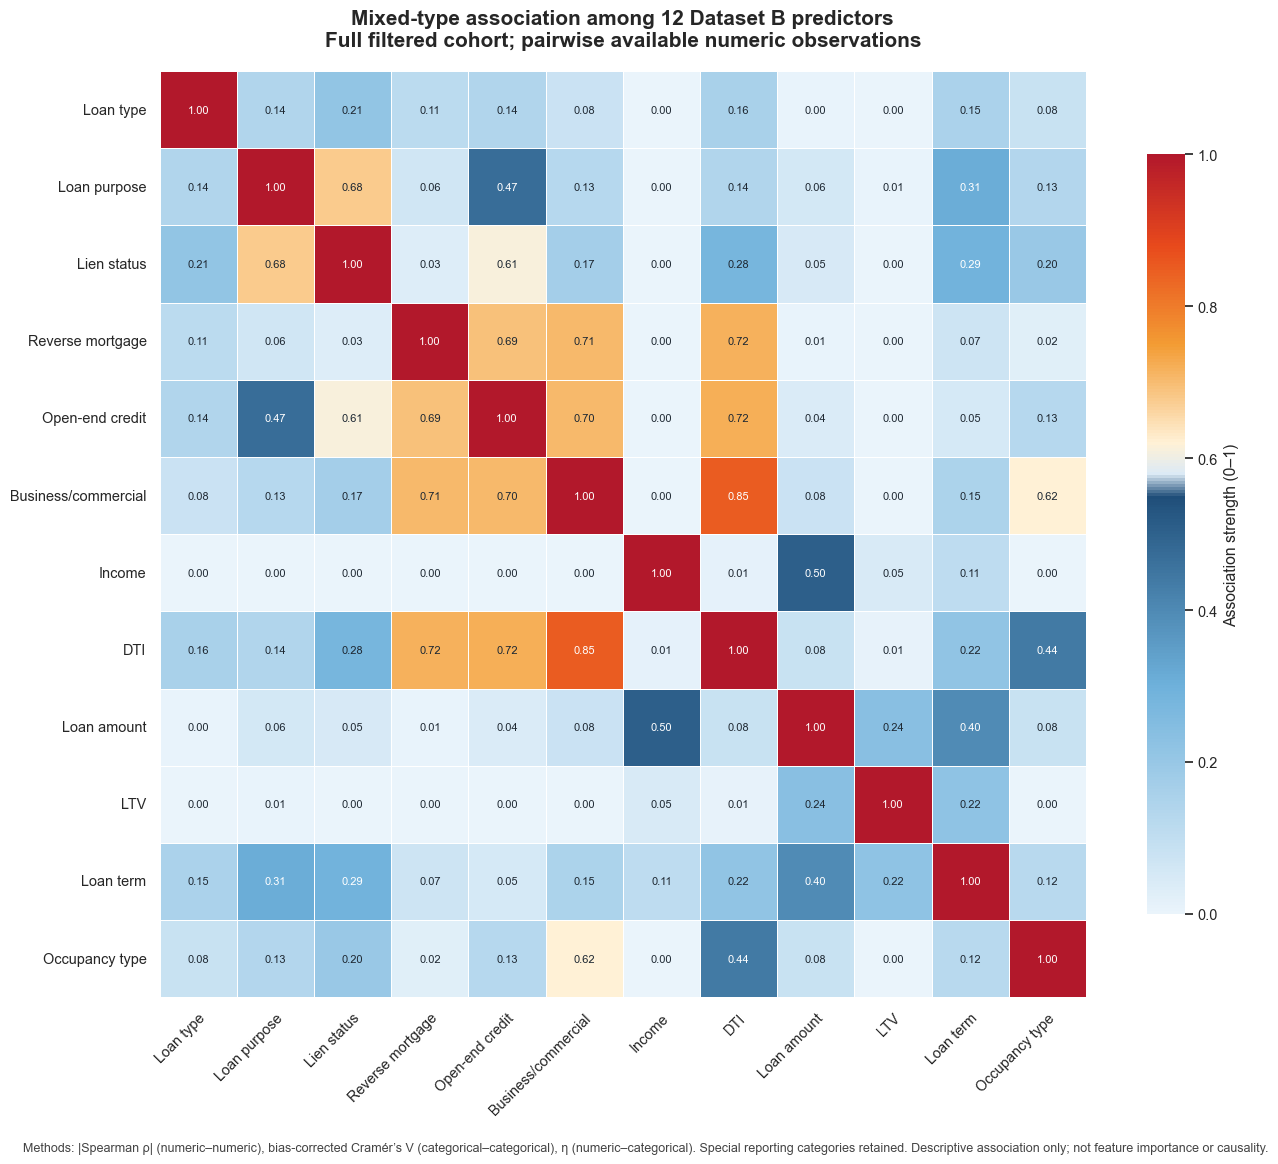

In [16]:
from matplotlib.colors import LinearSegmentedColormap

association_labels = [
    EDA_FEATURE_LABELS[feature]
    for feature in EDA_ASSOCIATION_FEATURES
]
association_for_plot = eda_association_strength.copy()
association_for_plot.index = association_labels
association_for_plot.columns = association_labels

association_cmap = LinearSegmentedColormap.from_list(
    "cool_blue_orange_red",
    [
        (0.00, "#EAF4FB"),
        (0.30, "#6EB1DB"),
        (0.55, "#1F4E79"),
        (0.58, "#DCEAF5"),
        (0.62, "#FFF1D6"),
        (0.75, "#F39C34"),
        (0.88, "#E84A1C"),
        (1.00, "#B2182B"),
    ],
)

sns.set_theme(
    style="white",
    context="notebook",
    font_scale=0.95,
)
eda_task_03_figure, association_axis = plt.subplots(
    figsize=(14, 12)
)
sns.heatmap(
    association_for_plot,
    ax=association_axis,
    cmap=association_cmap,
    vmin=0,
    vmax=1,
    square=True,
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 8},
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Association strength (0–1)",
        "shrink": 0.82,
    },
)

for annotation, value in zip(
    association_axis.texts,
    association_for_plot.to_numpy().ravel(),
):
    use_white_text = (0.28 <= value <= 0.55) or value >= 0.82
    annotation.set_color(
        "white" if use_white_text else "#1F2933"
    )

association_axis.set_title(
    "Mixed-type association among 12 Dataset B predictors\n"
    "Full filtered cohort; pairwise available numeric observations",
    fontsize=15,
    fontweight="bold",
    pad=18,
)
association_axis.set_xlabel("")
association_axis.set_ylabel("")
association_axis.set_xticklabels(
    association_axis.get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor",
)
association_axis.set_yticklabels(
    association_axis.get_yticklabels(),
    rotation=0,
)
eda_task_03_figure.text(
    0.5,
    0.015,
    (
        "Methods: |Spearman ρ| (numeric–numeric), "
        "bias-corrected Cramér’s V (categorical–categorical), "
        "η (numeric–categorical). Special reporting categories retained. "
        "Descriptive association only; not feature importance or causality."
    ),
    ha="center",
    va="bottom",
    fontsize=9,
    color="#444444",
)
eda_task_03_figure.tight_layout(rect=(0, 0.055, 1, 0.96))
plt.show()


**Figure 1 — Mixed-type association among the 12 Dataset B predictors.** Population: full filtered Dataset B cohort, `n = 293,301`; pairwise available `n = 255,305–293,301`. Feature version: `temporary_training_lock_v0_2`. Statistics: absolute Spearman ρ for numeric–numeric pairs, bias-corrected Cramér’s V for categorical–categorical pairs and correlation ratio η for numeric–categorical pairs. Special states (`NA`, `Exempt`, `1111`) are retained as explicit raw categories where applicable; numeric special states are unavailable for pairwise numeric calculation. View: full-cohort pairwise association, not a train/model view. **Association strength is descriptive and must not be interpreted as feature importance or evidence of causality.**


### Observed interpretation

- Full-cohort association mạnh nhất là `business_or_commercial_purpose` × `debt_to_income_ratio` với bias-corrected Cramér’s V = 0,8493. Khi chỉ giữ informative categories, V giảm còn 0,0896; chênh lệch 0,7598 cho thấy heatmap full-cohort chủ yếu phản ánh reporting-state overlap ở cặp này.
- Các cặp giữa ba transaction flags cũng giảm rõ sau khi bỏ special states: full-cohort V khoảng 0,6950–0,7060, trong khi informative-only V khoảng 0,0162–0,1635. Vì vậy không được diễn giải các ô đậm này như bằng chứng các feature có ý nghĩa nghiệp vụ giống nhau.
- Trong bốn numeric features, liên hệ có dấu mạnh nhất là `income` × `loan_amount` với Spearman ρ = 0,5039; tiếp theo là `loan_amount` × `loan_term` với ρ = 0,3976. `loan_amount` × LTV có ρ = 0,2359.
- Pairwise denominator nằm trong khoảng 255.305–293.301 hồ sơ. Khác biệt denominator đến từ `NA`/`Exempt` của numeric features, không phải do dùng train/test split.

Các kết quả trên mô tả association của full Dataset B cohort. Chúng không thay đổi feature-selection decision và không chứng minh feature importance hoặc quan hệ nhân quả.


### 12. Task 03 acceptance gate

Gate cuối xác nhận figure sử dụng đúng 12 predictors và toàn bộ Task 02 views vẫn bất biến sau khi tính association.


In [17]:
pd.testing.assert_frame_equal(
    eda_numeric_view,
    eda_task_03_numeric_before,
)
pd.testing.assert_frame_equal(
    eda_numeric_status_view,
    eda_task_03_status_before,
)
pd.testing.assert_frame_equal(
    eda_categorical_view,
    eda_task_03_categorical_before,
)
assert len(eda_task_03_figure.axes) == 2
assert association_axis.get_title().startswith(
    "Mixed-type association"
)
assert eda_forbidden_figure_columns.isdisjoint(
    eda_association_strength.columns
)

strongest_pair = eda_top_association_pairs.iloc[0]
largest_special_effect = eda_categorical_sensitivity.iloc[0]
eda_task_03_summary = pd.Series(
    {
        "dataset_b_rows": EXPECTED_DATASET_B_ROWS,
        "association_feature_count": len(
            EDA_ASSOCIATION_FEATURES
        ),
        "unique_pair_count": len(
            eda_association_pairs
        ),
        "minimum_pair_n": int(
            eda_association_pairs["n"].min()
        ),
        "maximum_pair_n": int(
            eda_association_pairs["n"].max()
        ),
        "strongest_pair": (
            f"{strongest_pair['left']} × "
            f"{strongest_pair['right']}"
        ),
        "strongest_pair_method": strongest_pair["method"],
        "strongest_pair_strength": float(
            strongest_pair["association_strength"]
        ),
        "largest_special_effect_pair": (
            f"{largest_special_effect['left']} × "
            f"{largest_special_effect['right']}"
        ),
        "largest_special_effect_delta": float(
            largest_special_effect[
                "full_minus_informative"
            ]
        ),
        "target_used": False,
        "feature_selection_changed": False,
        "task_02_views_unchanged": True,
        "figure_created": True,
    },
    name="Task 03 acceptance summary",
)

print("[DATA QUALITY] Task 03 acceptance summary")
print(eda_task_03_summary.to_string())
print("[PASS] The 12x12 research heatmap uses only the predictor contract.")
print("[PASS] Task 02 numeric, status, and categorical views are unchanged.")
print("[PASS] Task 03 did not use target or alter feature-selection decisions.")


[DATA QUALITY] Task 03 acceptance summary
dataset_b_rows                                                             293301
association_feature_count                                                      12
unique_pair_count                                                              66
minimum_pair_n                                                             255305
maximum_pair_n                                                             293301
strongest_pair                  business_or_commercial_purpose × debt_to_incom...
strongest_pair_method                                    bias_corrected_cramers_v
strongest_pair_strength                                                  0.849313
largest_special_effect_pair     business_or_commercial_purpose × debt_to_incom...
largest_special_effect_delta                                             0.759756
target_used                                                                 False
feature_selection_changed                               

## Task 03 stop point

Task 03 dừng sau mixed-type association matrix, signed numeric Spearman table và acceptance gate. Chưa tạo boxplot/KDE/count plots, chưa phân tích target/protected groups và chưa ghi figure thành file ngoài notebook.


## Task 04 — Numeric distributions for research

Bốn numeric predictors được mô tả từ full Dataset B cohort sau filter, không dùng Train/Validation/Test và không dùng preprocessing của model. Mỗi feature có một full-range view giữ toàn bộ observed numeric values và một central view chỉ giới hạn cửa sổ hiển thị. Số quan sát ngoài central window được ghi trực tiếp trên hình.

Các statistic trong notebook 04 chỉ là mốc consistency. Task 04 không xuất lại `income_distribution_4_3`, `distribution_4_4` hoặc `distribution_4_5`, và không thực hiện feature screening mới.


In [18]:
from matplotlib.ticker import FuncFormatter, PercentFormatter

eda_task_04_required = {
    "eda_numeric_view",
    "eda_numeric_status_view",
    "eda_categorical_view",
    "EDA_NUMERIC_FEATURES",
    "EXPECTED_DATASET_B_ROWS",
    "eda_forbidden_figure_columns",
}
eda_task_04_missing = sorted(
    name
    for name in eda_task_04_required
    if name not in globals()
)
assert not eda_task_04_missing, (
    "Run Tasks 01–03 first. Missing variables: "
    f"{eda_task_04_missing}"
)

EDA_TASK_04_FEATURES = (
    "income",
    "loan_amount",
    "loan_to_value_ratio",
    "loan_term",
)
assert EDA_TASK_04_FEATURES == EDA_NUMERIC_FEATURES

EDA_TASK_04_REFERENCE_FROM_04 = {
    "income": {
        "numeric_n": 272_723,
        "negative_n": 360,
        "zero_n": 3_111,
        "minimum": -11_229.0,
        "median": 120.0,
        "p99": 1_242.0,
        "maximum": 100_000_000.0,
    },
    "loan_amount": {
        "numeric_n": 293_301,
        "minimum": 5_000.0,
        "median": 205_000.0,
        "p99": 2_435_000.0,
        "maximum": 600_855_000.0,
    },
    "loan_to_value_ratio": {
        "numeric_n": 274_681,
        "minimum": 0.001,
        "median": 74.99,
        "p99": 105.021,
        "maximum": 2_000_000.0,
        "above_100_n": 5_261,
        "above_200_n": 246,
        "above_1000_n": 60,
    },
    "loan_term": {
        "numeric_n": 274_648,
        "minimum": 1.0,
        "median": 360.0,
        "p99": 360.0,
        "maximum": 900.0,
    },
}

EDA_TASK_04_COLORS = {
    "full": "#2F6B9A",
    "central": "#F28E2B",
    "density": "#B2182B",
    "ecdf": "#1F4E79",
    "reference": "#C53B20",
    "text": "#24313D",
}

eda_task_04_numeric_before = eda_numeric_view.copy(deep=True)
eda_task_04_status_before = eda_numeric_status_view.copy(deep=True)
eda_task_04_categorical_before = eda_categorical_view.copy(deep=True)

print("[PASS] Task 02 plot-ready views are available for Task 04.")
print("[PASS] Task 04 is limited to four numeric predictors and uses no split artifact.")
print("[PASS] Notebook 04 values are consistency references, not screening outputs.")


[PASS] Task 02 plot-ready views are available for Task 04.
[PASS] Task 04 is limited to four numeric predictors and uses no split artifact.
[PASS] Notebook 04 values are consistency references, not screening outputs.


In [19]:
eda_task_04_observed = {
    feature: (
        eda_numeric_view[feature]
        .dropna()
        .astype("float64")
        .copy()
    )
    for feature in EDA_TASK_04_FEATURES
}

eda_task_04_windows = {
    "income": (
        float(eda_task_04_observed["income"].quantile(0.01)),
        float(eda_task_04_observed["income"].quantile(0.99)),
    ),
    "loan_amount": (
        float(eda_task_04_observed["loan_amount"].quantile(0.01)),
        float(eda_task_04_observed["loan_amount"].quantile(0.99)),
    ),
    "loan_to_value_ratio": (0.0, 250.0),
    "loan_term": (
        float(eda_task_04_observed["loan_term"].quantile(0.01)),
        float(eda_task_04_observed["loan_term"].quantile(0.99)),
    ),
}

eda_task_04_window_rows = []
for feature, observed in eda_task_04_observed.items():
    lower, upper = eda_task_04_windows[feature]
    central_mask = observed.between(lower, upper, inclusive="both")
    outside_n = int((~central_mask).sum())
    eda_task_04_window_rows.append(
        {
            "feature": feature,
            "observed_n": len(observed),
            "window_lower": lower,
            "window_upper": upper,
            "central_n": int(central_mask.sum()),
            "outside_n": outside_n,
            "outside_pct": outside_n / len(observed) * 100,
        }
    )

eda_task_04_window_summary = (
    pd.DataFrame(eda_task_04_window_rows)
    .set_index("feature")
)

def eda_task_04_assert_close(observed, expected, label, atol=1e-6):
    assert np.isclose(observed, expected, rtol=0, atol=atol), (
        f"{label}: observed={observed}, expected={expected}"
    )


for feature, expected in EDA_TASK_04_REFERENCE_FROM_04.items():
    observed = eda_task_04_observed[feature]
    assert len(observed) == expected["numeric_n"]
    eda_task_04_assert_close(
        observed.min(), expected["minimum"], f"{feature}.minimum"
    )
    eda_task_04_assert_close(
        observed.median(), expected["median"], f"{feature}.median"
    )
    eda_task_04_assert_close(
        observed.quantile(0.99),
        expected["p99"],
        f"{feature}.p99",
        atol=1e-3,
    )
    eda_task_04_assert_close(
        observed.max(), expected["maximum"], f"{feature}.maximum"
    )

income_observed = eda_task_04_observed["income"]
assert int(income_observed.lt(0).sum()) == 360
assert int(income_observed.eq(0).sum()) == 3_111

ltv_observed = eda_task_04_observed["loan_to_value_ratio"]
assert int(ltv_observed.gt(100).sum()) == 5_261
assert int(ltv_observed.gt(200).sum()) == 246
assert int(ltv_observed.gt(1_000).sum()) == 60

def eda_task_04_central_values(feature):
    values = eda_task_04_observed[feature]
    lower, upper = eda_task_04_windows[feature]
    return values.loc[values.between(lower, upper, inclusive="both")]


def eda_task_04_format_number(value):
    if abs(value) >= 1_000:
        return f"{value:,.0f}"
    return f"{value:,.3f}".rstrip("0").rstrip(".")


def eda_task_04_window_note(feature):
    row = eda_task_04_window_summary.loc[feature]
    return (
        f"Central window: {eda_task_04_format_number(row['window_lower'])} "
        f"to {eda_task_04_format_number(row['window_upper'])}; "
        f"outside window: {int(row['outside_n']):,} "
        f"({row['outside_pct']:.2f}% of observed numeric values)."
    )


def eda_task_04_draw_full_box(axis, values, color, scale, linthresh=None):
    axis.boxplot(
        values.to_numpy(),
        orientation="horizontal",
        whis=(0, 100),
        showfliers=False,
        widths=0.38,
        patch_artist=True,
        boxprops={"facecolor": color, "alpha": 0.72},
        medianprops={"color": "#111111", "linewidth": 1.8},
        whiskerprops={"color": color, "linewidth": 1.4},
        capprops={"color": color, "linewidth": 1.4},
    )
    if scale == "symlog":
        axis.set_xscale("symlog", linthresh=linthresh)
    else:
        axis.set_xscale(scale)
    axis.set_yticks([])
    axis.grid(True, axis="x", alpha=0.22)


def eda_task_04_draw_ecdf(axis, values, color, scale, linthresh=None):
    unique_values, counts = np.unique(
        values.to_numpy(), return_counts=True
    )
    cumulative = np.cumsum(counts) / counts.sum()
    axis.step(
        unique_values,
        cumulative,
        where="post",
        color=color,
        linewidth=2.0,
    )
    if scale == "symlog":
        axis.set_xscale("symlog", linthresh=linthresh)
    else:
        axis.set_xscale(scale)
    axis.set_ylim(0, 1.01)
    axis.yaxis.set_major_formatter(PercentFormatter(1.0))
    axis.set_ylabel("Cumulative share")
    axis.grid(True, alpha=0.22)


sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=0.95,
)

print("[PASS] Minimal plot statistics match the saved notebook 04 references.")
print("[PASS] Full-range series retain every observed numeric value.")


[PASS] Minimal plot statistics match the saved notebook 04 references.
[PASS] Full-range series retain every observed numeric value.


### 13. Income — full range, central distribution and ECDF

Full range uses a symmetric-log axis so negative, zero and extreme positive values remain visible. The central histogram/KDE uses P1–P99 only for display; no row is removed from the full-range views.


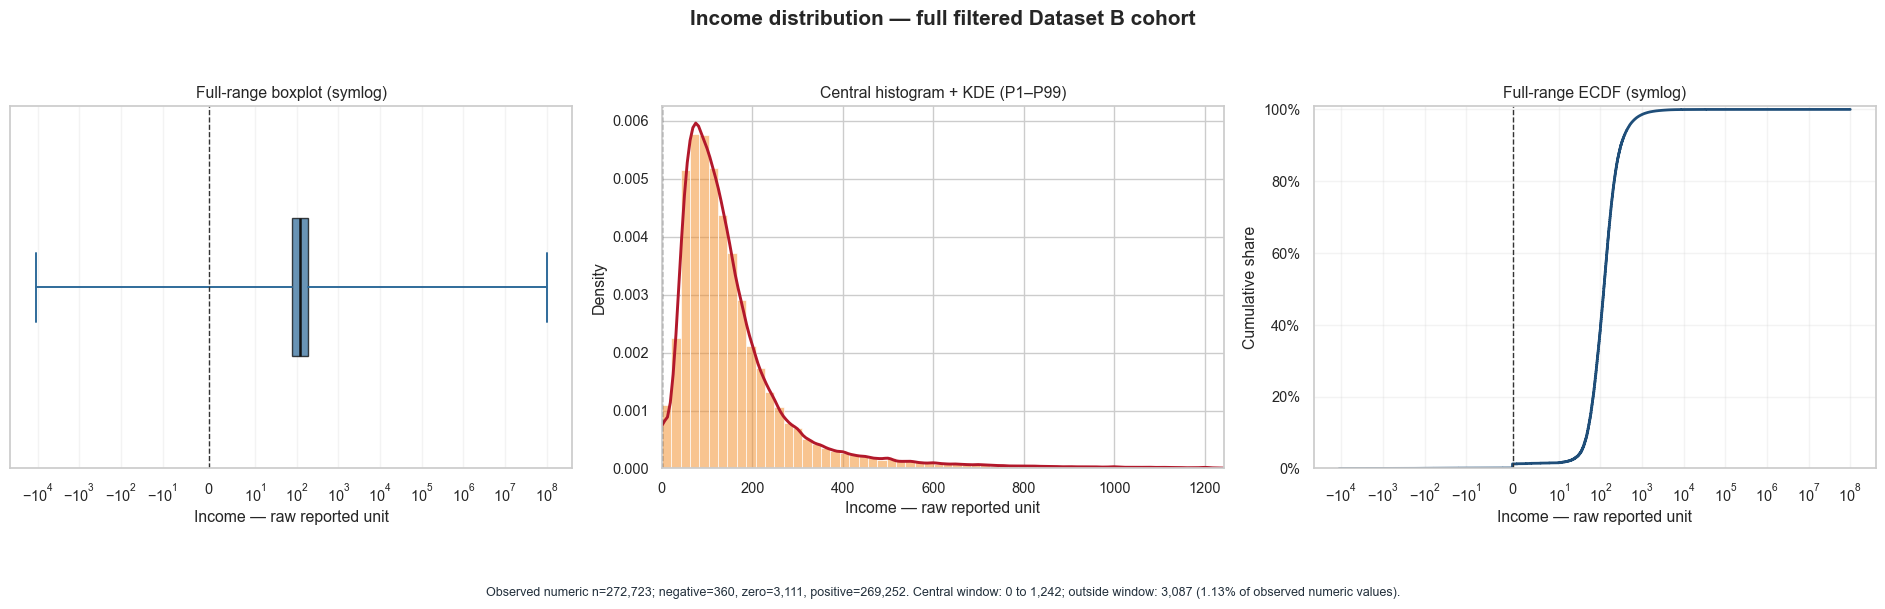

In [20]:
income_values = eda_task_04_observed["income"]
income_central = eda_task_04_central_values("income")
income_lower, income_upper = eda_task_04_windows["income"]

eda_task_04_income_figure, income_axes = plt.subplots(
    1, 3, figsize=(19, 5.6)
)

eda_task_04_draw_full_box(
    income_axes[0],
    income_values,
    EDA_TASK_04_COLORS["full"],
    scale="symlog",
    linthresh=10,
)
income_axes[0].axvline(0, color="#333333", linewidth=1, linestyle="--")
income_axes[0].set_title("Full-range boxplot (symlog)")
income_axes[0].set_xlabel("Income — raw reported unit")

sns.histplot(
    income_central,
    bins=60,
    stat="density",
    color=EDA_TASK_04_COLORS["central"],
    alpha=0.52,
    edgecolor="white",
    ax=income_axes[1],
)
sns.kdeplot(
    income_central,
    color=EDA_TASK_04_COLORS["density"],
    linewidth=2.1,
    bw_adjust=0.75,
    cut=0,
    clip=(income_lower, income_upper),
    warn_singular=False,
    ax=income_axes[1],
)
income_axes[1].axvline(0, color="#333333", linewidth=1, linestyle="--")
income_axes[1].set_xlim(income_lower, income_upper)
income_axes[1].set_title("Central histogram + KDE (P1–P99)")
income_axes[1].set_xlabel("Income — raw reported unit")
income_axes[1].set_ylabel("Density")

eda_task_04_draw_ecdf(
    income_axes[2],
    income_values,
    EDA_TASK_04_COLORS["ecdf"],
    scale="symlog",
    linthresh=10,
)
income_axes[2].axvline(0, color="#333333", linewidth=1, linestyle="--")
income_axes[2].set_title("Full-range ECDF (symlog)")
income_axes[2].set_xlabel("Income — raw reported unit")

income_negative_n = int(income_values.lt(0).sum())
income_zero_n = int(income_values.eq(0).sum())
income_positive_n = int(income_values.gt(0).sum())

eda_task_04_income_figure.suptitle(
    "Income distribution — full filtered Dataset B cohort",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
eda_task_04_income_figure.text(
    0.5,
    -0.01,
    (
        f"Observed numeric n={len(income_values):,}; "
        f"negative={income_negative_n:,}, zero={income_zero_n:,}, "
        f"positive={income_positive_n:,}. "
        + eda_task_04_window_note("income")
    ),
    ha="center",
    va="top",
    fontsize=9,
    color=EDA_TASK_04_COLORS["text"],
)
eda_task_04_income_figure.tight_layout(rect=(0, 0.07, 1, 0.98))
plt.show()


**Figure 2 — Income distribution.** Population: full filtered Dataset B cohort, `n = 293,301`; observed numeric `n = 272,723`. Feature version: `temporary_training_lock_v0_2`. Statistics: min–max boxplot on a symlog axis, P1–P99 histogram/KDE and full-range ECDF; negative/zero/positive counts are annotated. Special state: 20,578 `NA` values remain in the raw/status view and are excluded only from numeric plotting. View: full range plus central P1–P99; 3,087 observed values lie outside the central window. This is descriptive distribution evidence; any association reported in the notebook is not feature importance or causal evidence.


### 14. Loan amount — full range, central distribution and ECDF

Full-range boxplot and ECDF use a log x-axis because every observed value is positive and the maximum is far above P99. The central histogram/KDE uses P1–P99 for display only.


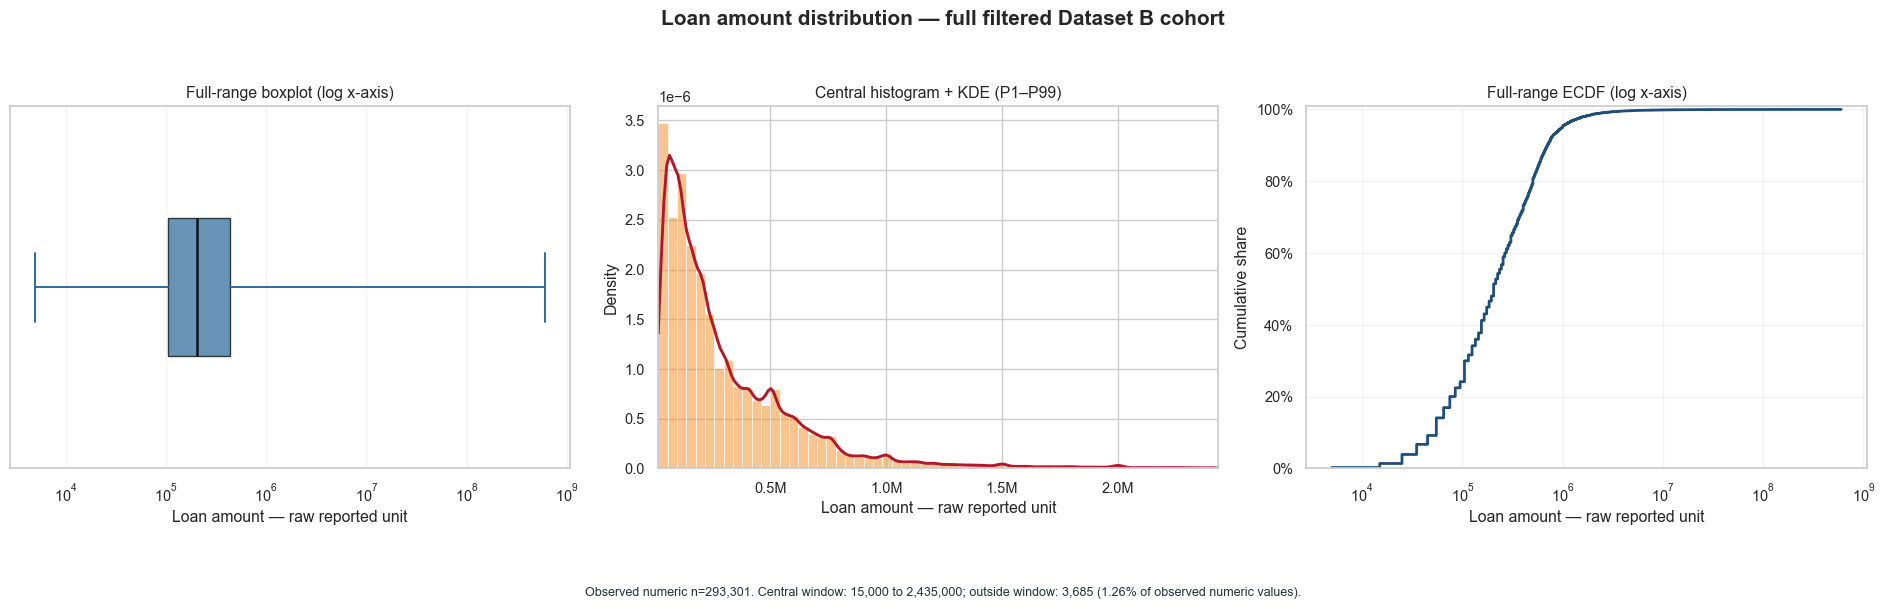

In [21]:
loan_amount_values = eda_task_04_observed["loan_amount"]
loan_amount_central = eda_task_04_central_values("loan_amount")
loan_amount_lower, loan_amount_upper = eda_task_04_windows["loan_amount"]
assert loan_amount_values.gt(0).all()

eda_task_04_loan_amount_figure, loan_amount_axes = plt.subplots(
    1, 3, figsize=(19, 5.6)
)

eda_task_04_draw_full_box(
    loan_amount_axes[0],
    loan_amount_values,
    EDA_TASK_04_COLORS["full"],
    scale="log",
)
loan_amount_axes[0].set_title("Full-range boxplot (log x-axis)")
loan_amount_axes[0].set_xlabel("Loan amount — raw reported unit")

sns.histplot(
    loan_amount_central,
    bins=60,
    stat="density",
    color=EDA_TASK_04_COLORS["central"],
    alpha=0.52,
    edgecolor="white",
    ax=loan_amount_axes[1],
)
sns.kdeplot(
    loan_amount_central,
    color=EDA_TASK_04_COLORS["density"],
    linewidth=2.1,
    bw_adjust=0.8,
    cut=0,
    clip=(loan_amount_lower, loan_amount_upper),
    warn_singular=False,
    ax=loan_amount_axes[1],
)
loan_amount_axes[1].set_xlim(loan_amount_lower, loan_amount_upper)
loan_amount_axes[1].xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value / 1_000_000:.1f}M")
)
loan_amount_axes[1].set_title("Central histogram + KDE (P1–P99)")
loan_amount_axes[1].set_xlabel("Loan amount — raw reported unit")
loan_amount_axes[1].set_ylabel("Density")

eda_task_04_draw_ecdf(
    loan_amount_axes[2],
    loan_amount_values,
    EDA_TASK_04_COLORS["ecdf"],
    scale="log",
)
loan_amount_axes[2].set_title("Full-range ECDF (log x-axis)")
loan_amount_axes[2].set_xlabel("Loan amount — raw reported unit")

eda_task_04_loan_amount_figure.suptitle(
    "Loan amount distribution — full filtered Dataset B cohort",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
eda_task_04_loan_amount_figure.text(
    0.5,
    -0.01,
    (
        f"Observed numeric n={len(loan_amount_values):,}. "
        + eda_task_04_window_note("loan_amount")
    ),
    ha="center",
    va="top",
    fontsize=9,
    color=EDA_TASK_04_COLORS["text"],
)
eda_task_04_loan_amount_figure.tight_layout(rect=(0, 0.07, 1, 0.98))
plt.show()


**Figure 3 — Loan amount distribution.** Population: full filtered Dataset B cohort, `n = 293,301`; observed numeric `n = 293,301`. Feature version: `temporary_training_lock_v0_2`. Statistics: min–max boxplot and ECDF on log x-axes, plus P1–P99 histogram/KDE. Special states: none for this feature. View: full range plus central P1–P99; 3,685 observations lie outside the central window. This is descriptive distribution evidence; any association reported in the notebook is not feature importance or causal evidence.


### 15. Loan-to-value ratio — full range, central KDE and ECDF

Full-range panels use a log x-axis and retain all positive observed values. Reference lines mark 100, 200 and 1.000. The central KDE uses 0–250 so the 100 and 200 reference levels remain visible; the 1.000 line appears only in the full-range panels because it is outside the central window.


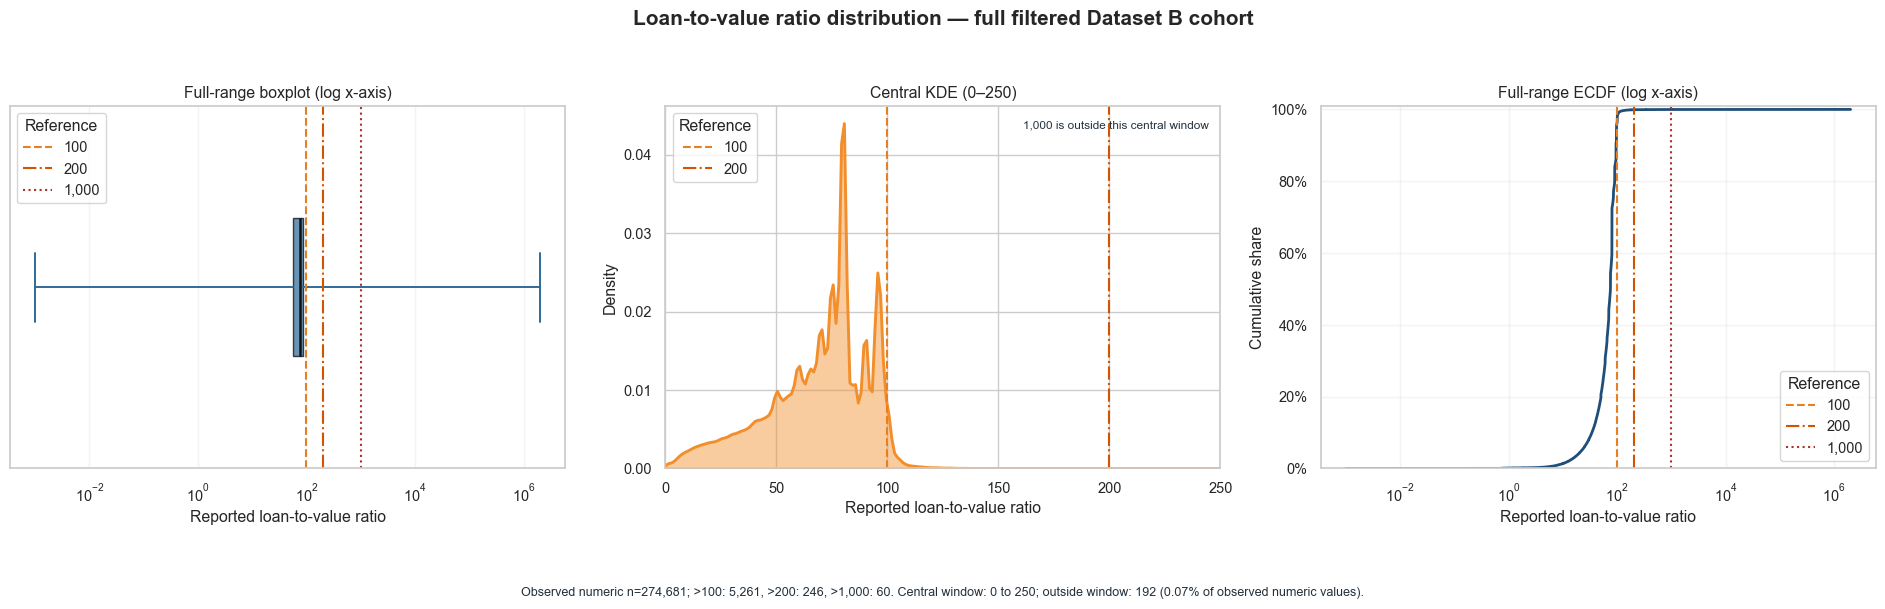

In [22]:
ltv_values = eda_task_04_observed["loan_to_value_ratio"]
ltv_central = eda_task_04_central_values("loan_to_value_ratio")
ltv_lower, ltv_upper = eda_task_04_windows["loan_to_value_ratio"]
assert ltv_values.gt(0).all()

ltv_reference_lines = {
    100.0: ("100", "#E67E22", "--"),
    200.0: ("200", "#D35400", "-."),
    1_000.0: ("1,000", "#A93226", ":"),
}

eda_task_04_ltv_figure, ltv_axes = plt.subplots(
    1, 3, figsize=(19, 5.6)
)

eda_task_04_draw_full_box(
    ltv_axes[0],
    ltv_values,
    EDA_TASK_04_COLORS["full"],
    scale="log",
)
for reference, (label, color, linestyle) in ltv_reference_lines.items():
    ltv_axes[0].axvline(
        reference,
        color=color,
        linestyle=linestyle,
        linewidth=1.5,
        label=label,
    )
ltv_axes[0].set_title("Full-range boxplot (log x-axis)")
ltv_axes[0].set_xlabel("Reported loan-to-value ratio")
ltv_axes[0].legend(title="Reference", loc="upper left")

sns.kdeplot(
    ltv_central,
    fill=True,
    color=EDA_TASK_04_COLORS["central"],
    alpha=0.45,
    linewidth=2.1,
    bw_adjust=0.7,
    cut=0,
    clip=(ltv_lower, ltv_upper),
    warn_singular=False,
    ax=ltv_axes[1],
)
for reference in (100.0, 200.0):
    label, color, linestyle = ltv_reference_lines[reference]
    ltv_axes[1].axvline(
        reference,
        color=color,
        linestyle=linestyle,
        linewidth=1.5,
        label=label,
    )
ltv_axes[1].set_xlim(ltv_lower, ltv_upper)
ltv_axes[1].set_title("Central KDE (0–250)")
ltv_axes[1].set_xlabel("Reported loan-to-value ratio")
ltv_axes[1].set_ylabel("Density")
ltv_axes[1].legend(title="Reference", loc="upper left")
ltv_axes[1].text(
    0.98,
    0.96,
    "1,000 is outside this central window",
    transform=ltv_axes[1].transAxes,
    ha="right",
    va="top",
    fontsize=8.5,
    color=EDA_TASK_04_COLORS["text"],
)

eda_task_04_draw_ecdf(
    ltv_axes[2],
    ltv_values,
    EDA_TASK_04_COLORS["ecdf"],
    scale="log",
)
for reference, (label, color, linestyle) in ltv_reference_lines.items():
    ltv_axes[2].axvline(
        reference,
        color=color,
        linestyle=linestyle,
        linewidth=1.5,
        label=label,
    )
ltv_axes[2].set_title("Full-range ECDF (log x-axis)")
ltv_axes[2].set_xlabel("Reported loan-to-value ratio")
ltv_axes[2].legend(title="Reference", loc="lower right")

eda_task_04_ltv_figure.suptitle(
    "Loan-to-value ratio distribution — full filtered Dataset B cohort",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
eda_task_04_ltv_figure.text(
    0.5,
    -0.01,
    (
        f"Observed numeric n={len(ltv_values):,}; "
        f">100: {int(ltv_values.gt(100).sum()):,}, "
        f">200: {int(ltv_values.gt(200).sum()):,}, "
        f">1,000: {int(ltv_values.gt(1_000).sum()):,}. "
        + eda_task_04_window_note("loan_to_value_ratio")
    ),
    ha="center",
    va="top",
    fontsize=9,
    color=EDA_TASK_04_COLORS["text"],
)
eda_task_04_ltv_figure.tight_layout(rect=(0, 0.07, 1, 0.98))
plt.show()


**Figure 4 — Loan-to-value ratio distribution.** Population: full filtered Dataset B cohort, `n = 293,301`; observed numeric `n = 274,681`. Feature version: `temporary_training_lock_v0_2`. Statistics: min–max boxplot and ECDF on log x-axes, central KDE and reference lines at 100, 200 and 1,000. Special states: 9,978 `NA` and 8,642 `Exempt` values remain explicit in the raw/status view and are excluded only from numeric plotting. View: full range plus central 0–250; 192 observed values lie outside the central window. This is descriptive distribution evidence; any association reported in the notebook is not feature importance or causal evidence.


### 16. Loan term — boxplot, frequency histogram and ECDF

`loan_term` được giữ ở raw reported unit. Full-range boxplot và ECDF giữ toàn bộ observed numeric values; frequency histogram tập trung vào P1–P99. KDE không được dùng vì feature rời rạc và tập trung mạnh ở một số giá trị hợp đồng.


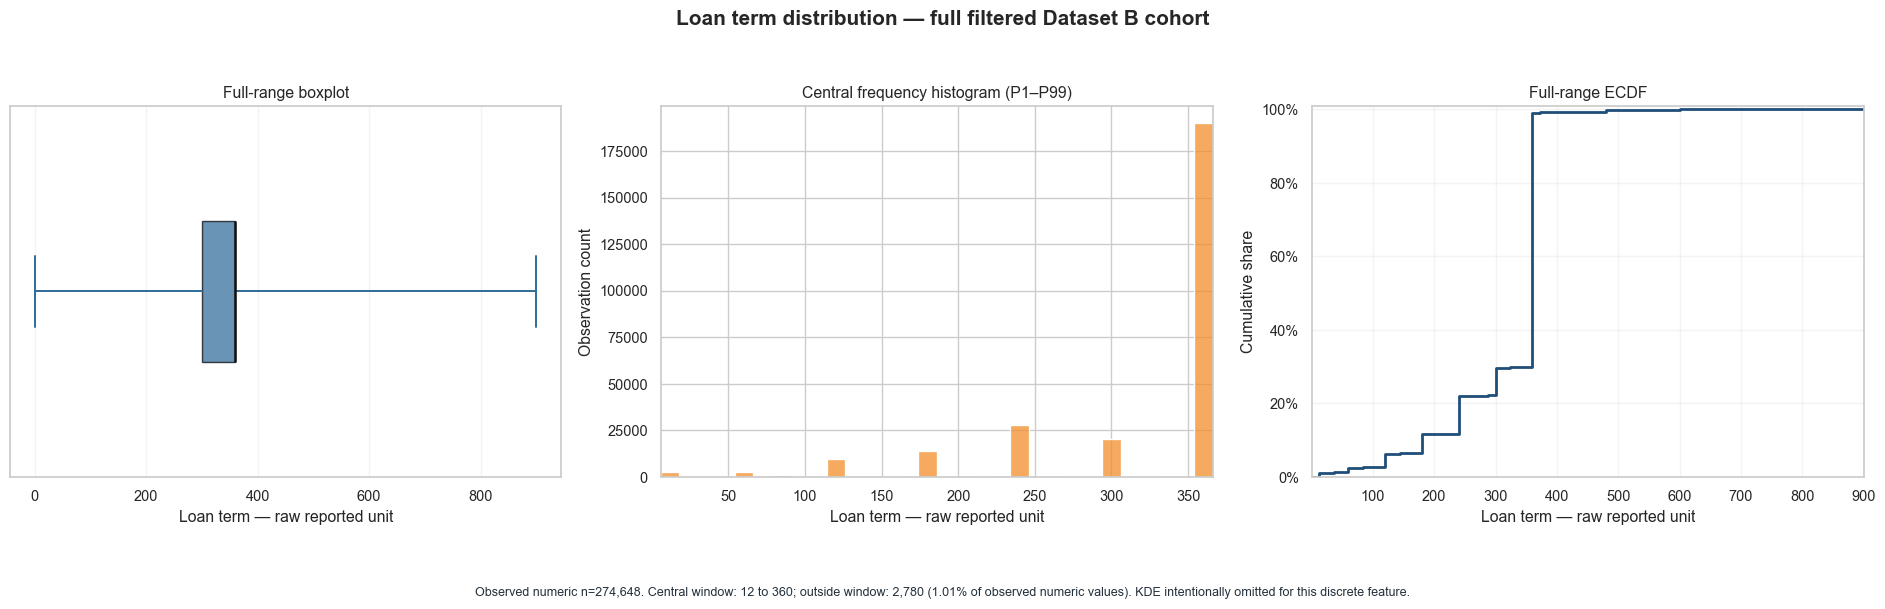

In [23]:
loan_term_values = eda_task_04_observed["loan_term"]
loan_term_central = eda_task_04_central_values("loan_term")
loan_term_lower, loan_term_upper = eda_task_04_windows["loan_term"]

eda_task_04_loan_term_figure, loan_term_axes = plt.subplots(
    1, 3, figsize=(19, 5.6)
)

eda_task_04_draw_full_box(
    loan_term_axes[0],
    loan_term_values,
    EDA_TASK_04_COLORS["full"],
    scale="linear",
)
loan_term_axes[0].set_title("Full-range boxplot")
loan_term_axes[0].set_xlabel("Loan term — raw reported unit")

loan_term_bins = np.arange(
    loan_term_lower - 6,
    loan_term_upper + 18,
    12,
)
sns.histplot(
    loan_term_central,
    bins=loan_term_bins,
    stat="count",
    color=EDA_TASK_04_COLORS["central"],
    alpha=0.75,
    edgecolor="white",
    ax=loan_term_axes[1],
)
loan_term_axes[1].set_xlim(
    loan_term_lower - 6,
    loan_term_upper + 6,
)
loan_term_axes[1].set_title("Central frequency histogram (P1–P99)")
loan_term_axes[1].set_xlabel("Loan term — raw reported unit")
loan_term_axes[1].set_ylabel("Observation count")

eda_task_04_draw_ecdf(
    loan_term_axes[2],
    loan_term_values,
    EDA_TASK_04_COLORS["ecdf"],
    scale="linear",
)
loan_term_axes[2].set_xlim(
    loan_term_values.min(),
    loan_term_values.max(),
)
loan_term_axes[2].set_title("Full-range ECDF")
loan_term_axes[2].set_xlabel("Loan term — raw reported unit")

eda_task_04_loan_term_figure.suptitle(
    "Loan term distribution — full filtered Dataset B cohort",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
eda_task_04_loan_term_figure.text(
    0.5,
    -0.01,
    (
        f"Observed numeric n={len(loan_term_values):,}. "
        + eda_task_04_window_note("loan_term")
        + " KDE intentionally omitted for this discrete feature."
    ),
    ha="center",
    va="top",
    fontsize=9,
    color=EDA_TASK_04_COLORS["text"],
)
eda_task_04_loan_term_figure.tight_layout(rect=(0, 0.07, 1, 0.98))
plt.show()


**Figure 5 — Loan term distribution.** Population: full filtered Dataset B cohort, `n = 293,301`; observed numeric `n = 274,648`. Feature version: `temporary_training_lock_v0_2`. Statistics: min–max boxplot, P1–P99 frequency histogram and full-range ECDF; KDE is intentionally omitted for this discrete feature. Special states: 10,360 `NA` and 8,293 `Exempt` values remain explicit in the raw/status view and are excluded only from numeric plotting. View: full range plus central 12–360; 2,780 observed values lie outside the central window. This is descriptive distribution evidence; any association reported in the notebook is not feature importance or causal evidence.


### 17. Task 04 acceptance gate


In [24]:
pd.testing.assert_frame_equal(
    eda_numeric_view,
    eda_task_04_numeric_before,
)
pd.testing.assert_frame_equal(
    eda_numeric_status_view,
    eda_task_04_status_before,
)
pd.testing.assert_frame_equal(
    eda_categorical_view,
    eda_task_04_categorical_before,
)

for feature, row in eda_task_04_window_summary.iterrows():
    assert int(row["central_n"] + row["outside_n"]) == int(
        row["observed_n"]
    )
    assert row["outside_n"] > 0

for figure in (
    eda_task_04_income_figure,
    eda_task_04_loan_amount_figure,
    eda_task_04_ltv_figure,
    eda_task_04_loan_term_figure,
):
    assert len(figure.axes) == 3

assert eda_forbidden_figure_columns.isdisjoint(
    EDA_TASK_04_FEATURES
)
for forbidden_screening_table in (
    "income_distribution_4_3",
    "distribution_4_3",
    "distribution_4_4",
    "distribution_4_5",
):
    assert forbidden_screening_table not in globals()

eda_task_04_summary = pd.Series(
    {
        "dataset_b_rows": EXPECTED_DATASET_B_ROWS,
        "numeric_feature_count": len(EDA_TASK_04_FEATURES),
        "full_range_figures": 4,
        "central_views": 4,
        "ecdf_panels": 4,
        "kde_features": "income, loan_amount, loan_to_value_ratio",
        "loan_term_kde_used": False,
        "reference_values_match_notebook_04": True,
        "task_02_views_unchanged": True,
        "feature_screening_tables_recreated": False,
        "target_used": False,
        "split_artifact_used": False,
        "model_preprocessing_used": False,
    },
    name="Task 04 acceptance summary",
)

print("[DATA QUALITY] Task 04 central-view windows")
for feature, row in eda_task_04_window_summary.iterrows():
    print(
        f"[PASS] {feature}: observed={int(row['observed_n']):,}; "
        f"window=[{eda_task_04_format_number(row['window_lower'])}, "
        f"{eda_task_04_format_number(row['window_upper'])}]; "
        f"outside={int(row['outside_n']):,} "
        f"({row['outside_pct']:.2f}%)"
    )
print("[DATA QUALITY] Task 04 acceptance summary")
print(eda_task_04_summary.to_string())
print("[PASS] All four numeric research figures were rendered from full-cohort views.")
print("[PASS] Full-range and central counts reconcile for every feature.")
print("[PASS] Saved notebook 04 reference values match; screening tables were not recreated.")
print("[PASS] Task 02 views are unchanged; no target, split or model preprocessing was used.")


[DATA QUALITY] Task 04 central-view windows
[PASS] income: observed=272,723; window=[0, 1,242]; outside=3,087 (1.13%)
[PASS] loan_amount: observed=293,301; window=[15,000, 2,435,000]; outside=3,685 (1.26%)
[PASS] loan_to_value_ratio: observed=274,681; window=[0, 250]; outside=192 (0.07%)
[PASS] loan_term: observed=274,648; window=[12, 360]; outside=2,780 (1.01%)
[DATA QUALITY] Task 04 acceptance summary
dataset_b_rows                                                          293301
numeric_feature_count                                                        4
full_range_figures                                                           4
central_views                                                                4
ecdf_panels                                                                  4
kde_features                          income, loan_amount, loan_to_value_ratio
loan_term_kde_used                                                       False
reference_values_match_notebook_04      

## Task 04 stop point

Task 04 dừng sau bốn numeric distribution figures và acceptance gate. Các central windows chỉ giới hạn phần hiển thị; full-range boxplot/ECDF vẫn giữ toàn bộ observed numeric values. Chưa tạo categorical count plots, target-conditioned plots hoặc protected-group comparisons.


## Task 05 — Research-relevant categorical frequency figures

Task phụ này chỉ tạo bar charts từ raw frequency counts của full Dataset B cohort. Không xuất lại quality/decision tables, không tự gộp rare categories và không thay đổi feature-selection decisions. Các special states được giữ nguyên; `1111 = Exempt` dùng màu và hatch riêng.

Phạm vi hình được giới hạn ở ba nhóm có nội dung nghiên cứu rõ: transaction flags, loan type/purpose và occupancy. Caption chuẩn hóa cùng figure-supporting tables thuộc Task 06, chưa được tạo ở đây.


In [25]:
from matplotlib.patches import Patch

eda_task_05_required = {
    "eda_categorical_view",
    "eda_numeric_view",
    "eda_numeric_status_view",
    "EXPECTED_DATASET_B_ROWS",
    "eda_forbidden_figure_columns",
}
eda_task_05_missing = sorted(
    name
    for name in eda_task_05_required
    if name not in globals()
)
assert not eda_task_05_missing, (
    "Run Tasks 01–04 first. Missing variables: "
    f"{eda_task_05_missing}"
)

EDA_TASK_05_FEATURES = (
    "reverse_mortgage",
    "open-end_line_of_credit",
    "business_or_commercial_purpose",
    "loan_type",
    "loan_purpose",
    "occupancy_type",
)
EDA_TASK_05_TRANSACTION_FEATURES = (
    "reverse_mortgage",
    "open-end_line_of_credit",
    "business_or_commercial_purpose",
)
EDA_TASK_05_CATEGORY_ORDER = {
    "reverse_mortgage": ("1", "2", "1111"),
    "open-end_line_of_credit": ("1", "2", "1111"),
    "business_or_commercial_purpose": ("1", "2", "1111"),
    "loan_type": ("1", "2", "3", "4"),
    "loan_purpose": ("1", "2", "31", "32", "4", "5"),
    "occupancy_type": ("1", "2", "3"),
}
EDA_TASK_05_LABELS = {
    "reverse_mortgage": {
        "1": "Reverse mortgage",
        "2": "Not reverse mortgage",
        "1111": "Exempt (1111)",
    },
    "open-end_line_of_credit": {
        "1": "Open-end credit",
        "2": "Not open-end credit",
        "1111": "Exempt (1111)",
    },
    "business_or_commercial_purpose": {
        "1": "Business/commercial",
        "2": "Not business/commercial",
        "1111": "Exempt (1111)",
    },
    "loan_type": {
        "1": "Conventional",
        "2": "FHA",
        "3": "VA",
        "4": "RHS/FSA guaranteed",
    },
    "loan_purpose": {
        "1": "Home purchase",
        "2": "Home improvement",
        "31": "Refinancing",
        "32": "Cash-out refinancing",
        "4": "Other purpose",
        "5": "Not applicable",
    },
    "occupancy_type": {
        "1": "Principal residence",
        "2": "Second residence",
        "3": "Investment property",
    },
}
EDA_TASK_05_REFERENCE_COUNTS_FROM_04 = {
    "reverse_mortgage": {"1": 786, "2": 283_879, "1111": 8_636},
    "open-end_line_of_credit": {
        "1": 81_148,
        "2": 203_831,
        "1111": 8_322,
    },
    "business_or_commercial_purpose": {
        "1": 25_039,
        "2": 259_641,
        "1111": 8_621,
    },
    "loan_type": {
        "1": 265_629,
        "2": 21_121,
        "3": 6_208,
        "4": 343,
    },
    "loan_purpose": {
        "1": 139_144,
        "2": 49_762,
        "31": 29_412,
        "32": 34_595,
        "4": 40_360,
        "5": 28,
    },
    "occupancy_type": {
        "1": 257_433,
        "2": 7_100,
        "3": 28_768,
    },
}
EDA_TASK_05_SPECIAL_CODES = {
    feature: frozenset({"1111"})
    if feature in EDA_TASK_05_TRANSACTION_FEATURES
    else frozenset()
    for feature in EDA_TASK_05_FEATURES
}
EDA_TASK_05_COLORS = {
    "informative": "#2F6B9A",
    "special": "#F28E2B",
    "edge": "#34495E",
    "text": "#24313D",
}

eda_task_05_numeric_before = eda_numeric_view.copy(deep=True)
eda_task_05_status_before = eda_numeric_status_view.copy(deep=True)
eda_task_05_categorical_before = eda_categorical_view.copy(deep=True)

eda_task_05_frequency_rows = []
for feature in EDA_TASK_05_FEATURES:
    normalized = (
        eda_categorical_view[feature]
        .astype("string")
        .str.strip()
    )
    counts = normalized.value_counts(dropna=False)
    expected_codes = set(EDA_TASK_05_CATEGORY_ORDER[feature])
    observed_codes = set(counts.index.astype(str))
    assert observed_codes == expected_codes, (
        f"{feature}: observed={sorted(observed_codes)}, "
        f"expected={sorted(expected_codes)}"
    )

    for display_order, raw_code in enumerate(
        EDA_TASK_05_CATEGORY_ORDER[feature]
    ):
        count = int(counts.loc[raw_code])
        expected_count = EDA_TASK_05_REFERENCE_COUNTS_FROM_04[
            feature
        ][raw_code]
        assert count == expected_count, (
            f"{feature}.{raw_code}: observed={count}, "
            f"expected={expected_count}"
        )
        eda_task_05_frequency_rows.append(
            {
                "feature": feature,
                "raw_code": raw_code,
                "label": EDA_TASK_05_LABELS[feature][raw_code],
                "n": count,
                "share_pct": count / EXPECTED_DATASET_B_ROWS * 100,
                "is_special": raw_code
                in EDA_TASK_05_SPECIAL_CODES[feature],
                "display_order": display_order,
            }
        )

eda_task_05_frequency = pd.DataFrame(
    eda_task_05_frequency_rows
)

for feature in EDA_TASK_05_FEATURES:
    feature_counts = eda_task_05_frequency.loc[
        eda_task_05_frequency["feature"].eq(feature)
    ]
    assert int(feature_counts["n"].sum()) == EXPECTED_DATASET_B_ROWS
    assert len(feature_counts) == len(
        EDA_TASK_05_CATEGORY_ORDER[feature]
    )

def eda_task_05_plot_frequency_axis(axis, feature, title):
    plot_data = (
        eda_task_05_frequency.loc[
            eda_task_05_frequency["feature"].eq(feature)
        ]
        .sort_values("display_order")
        .reset_index(drop=True)
    )
    positions = np.arange(len(plot_data))
    colors = [
        EDA_TASK_05_COLORS["special"]
        if is_special
        else EDA_TASK_05_COLORS["informative"]
        for is_special in plot_data["is_special"]
    ]
    bars = axis.barh(
        positions,
        plot_data["n"],
        color=colors,
        edgecolor=EDA_TASK_05_COLORS["edge"],
        linewidth=0.8,
        height=0.64,
    )
    for bar, is_special in zip(bars, plot_data["is_special"]):
        if is_special:
            bar.set_hatch("///")

    axis.set_yticks(positions, plot_data["label"])
    axis.invert_yaxis()
    axis.set_title(title, fontsize=12, fontweight="bold")
    axis.set_xlabel("Record count")
    axis.set_ylabel("")
    axis.grid(True, axis="x", alpha=0.22)
    axis.grid(False, axis="y")
    maximum = float(plot_data["n"].max())
    axis.set_xlim(0, maximum * 1.27)
    axis.xaxis.set_major_formatter(
        FuncFormatter(
            lambda value, _: (
                f"{value / 1_000:.0f}k"
                if value >= 1_000
                else f"{value:.0f}"
            )
        )
    )
    for bar, row in zip(bars, plot_data.itertuples(index=False)):
        axis.text(
            bar.get_width() + maximum * 0.018,
            bar.get_y() + bar.get_height() / 2,
            f"{row.n:,} ({row.share_pct:.2f}%)",
            va="center",
            ha="left",
            fontsize=8.5,
            color=EDA_TASK_05_COLORS["text"],
        )
    return plot_data, bars


print("[PASS] Task 05 frequency counts match saved notebook 04 evidence.")
print("[PASS] Every raw category is retained in schema order; no rare-category grouping.")
print("[PASS] Task 06 captions and supporting tables remain outside this task.")


[PASS] Task 05 frequency counts match saved notebook 04 evidence.
[PASS] Every raw category is retained in schema order; no rare-category grouping.
[PASS] Task 06 captions and supporting tables remain outside this task.


### 18. Transaction flags — full-cohort frequency counts

The three flags are shown on a common count scale. `1111 = Exempt` remains visible as a valid special state and is distinguished by both orange fill and hatch.


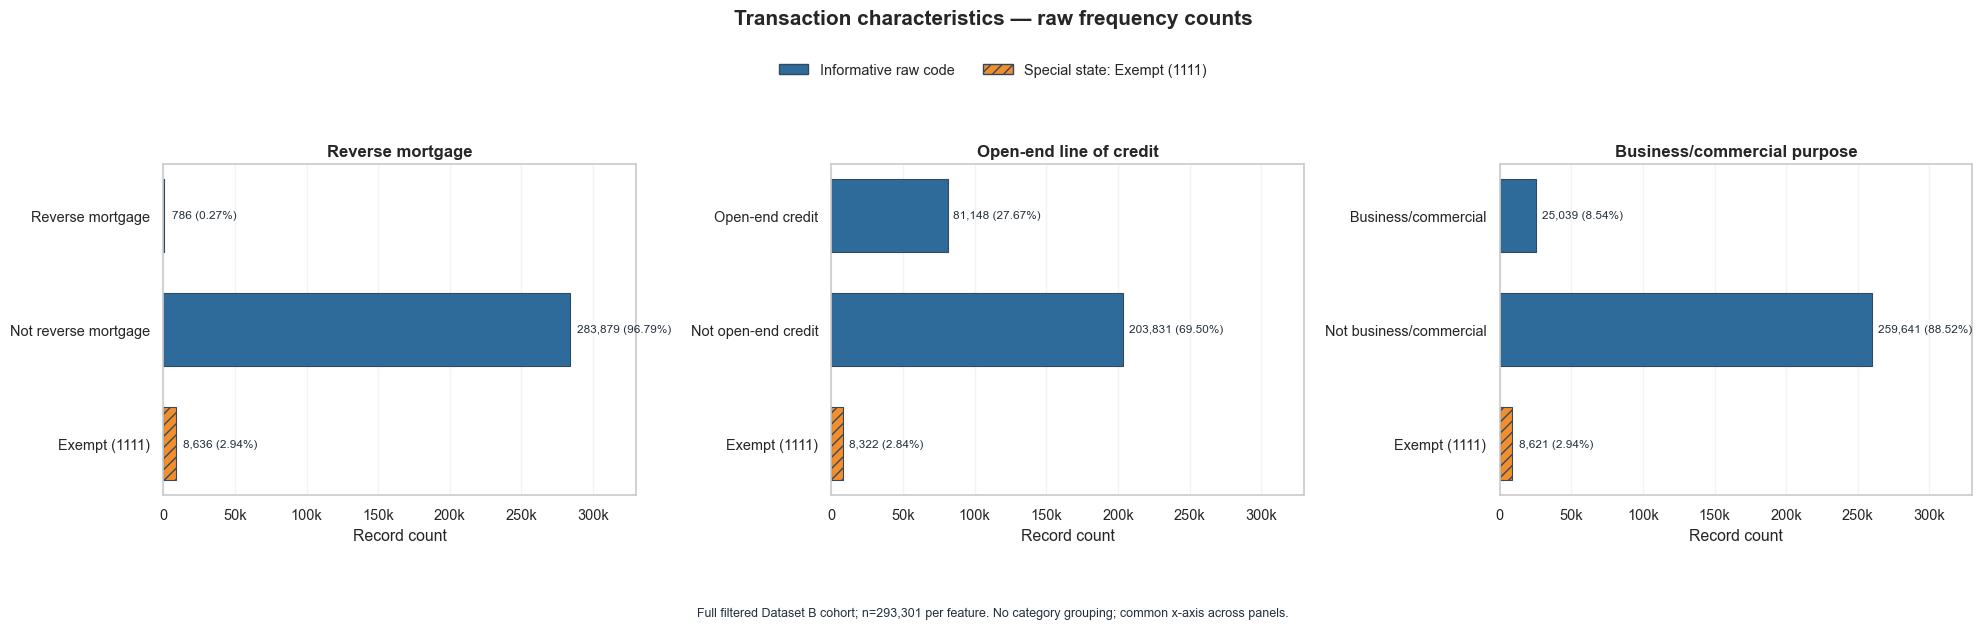

In [26]:
eda_task_05_transaction_figure, transaction_axes = plt.subplots(
    1, 3, figsize=(20, 5.8), sharex=True
)
transaction_titles = {
    "reverse_mortgage": "Reverse mortgage",
    "open-end_line_of_credit": "Open-end line of credit",
    "business_or_commercial_purpose": "Business/commercial purpose",
}
eda_task_05_transaction_plot_data = {}

for axis, feature in zip(
    transaction_axes,
    EDA_TASK_05_TRANSACTION_FEATURES,
):
    plot_data, _ = eda_task_05_plot_frequency_axis(
        axis,
        feature,
        transaction_titles[feature],
    )
    eda_task_05_transaction_plot_data[feature] = plot_data

transaction_legend = [
    Patch(
        facecolor=EDA_TASK_05_COLORS["informative"],
        edgecolor=EDA_TASK_05_COLORS["edge"],
        label="Informative raw code",
    ),
    Patch(
        facecolor=EDA_TASK_05_COLORS["special"],
        edgecolor=EDA_TASK_05_COLORS["edge"],
        hatch="///",
        label="Special state: Exempt (1111)",
    ),
]
eda_task_05_transaction_figure.legend(
    handles=transaction_legend,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.95),
    ncol=2,
    frameon=False,
)
eda_task_05_transaction_figure.suptitle(
    "Transaction characteristics — raw frequency counts",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
eda_task_05_transaction_figure.text(
    0.5,
    -0.01,
    (
        f"Full filtered Dataset B cohort; n={EXPECTED_DATASET_B_ROWS:,} "
        "per feature. No category grouping; common x-axis across panels."
    ),
    ha="center",
    va="top",
    fontsize=9,
    color=EDA_TASK_05_COLORS["text"],
)
eda_task_05_transaction_figure.tight_layout(
    rect=(0, 0.07, 1, 0.88)
)
plt.show()


**Figure 6 — Transaction-characteristic frequencies.** Population: full filtered Dataset B cohort, `n = 293,301` per feature. Feature version: `temporary_training_lock_v0_2`. Statistic: raw frequency count and cohort share for `reverse_mortgage`, `open-end_line_of_credit` and `business_or_commercial_purpose`. Special state: `1111 = Exempt` is retained as its own bar and distinguished by orange fill plus hatch; no rare category is grouped. View: full categorical range with a common count axis. These are descriptive frequencies; any association reported in the notebook is not feature importance or causal evidence.


### 19. Loan type and loan purpose — full-cohort frequency counts

All valid raw categories are retained, including the low-frequency `RHS/FSA guaranteed` and `Not applicable` categories. Panels use independent x-axes so rare categories remain readable through direct labels.


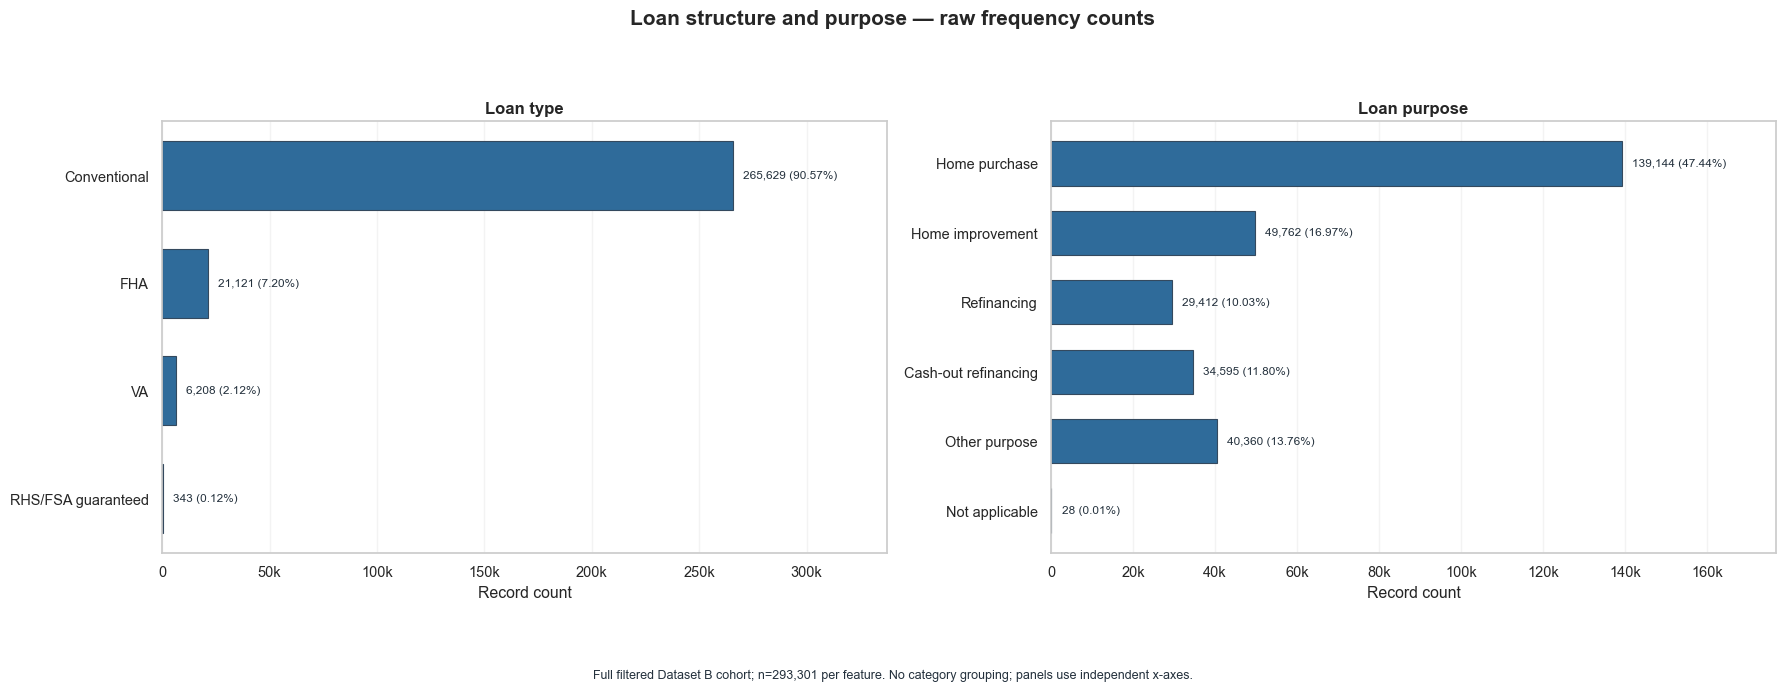

In [27]:
eda_task_05_product_figure, product_axes = plt.subplots(
    1, 2, figsize=(18, 6.4)
)
eda_task_05_loan_type_plot_data, _ = (
    eda_task_05_plot_frequency_axis(
        product_axes[0],
        "loan_type",
        "Loan type",
    )
)
eda_task_05_loan_purpose_plot_data, _ = (
    eda_task_05_plot_frequency_axis(
        product_axes[1],
        "loan_purpose",
        "Loan purpose",
    )
)

eda_task_05_product_figure.suptitle(
    "Loan structure and purpose — raw frequency counts",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
eda_task_05_product_figure.text(
    0.5,
    -0.01,
    (
        f"Full filtered Dataset B cohort; n={EXPECTED_DATASET_B_ROWS:,} "
        "per feature. No category grouping; panels use independent x-axes."
    ),
    ha="center",
    va="top",
    fontsize=9,
    color=EDA_TASK_05_COLORS["text"],
)
eda_task_05_product_figure.tight_layout(rect=(0, 0.07, 1, 0.96))
plt.show()


**Figure 7 — Loan type and loan purpose frequencies.** Population: full filtered Dataset B cohort, `n = 293,301` per feature. Feature version: `temporary_training_lock_v0_2`. Statistic: raw frequency count and cohort share. Special states: none in the agreed raw domains; all valid categories, including `RHS/FSA guaranteed` and `Not applicable`, are retained without grouping. View: full categorical range; panels use independent count axes and direct labels. These are descriptive frequencies; any association reported in the notebook is not feature importance or causal evidence.


### 20. Occupancy type — full-cohort frequency counts

The three valid occupancy categories are shown without grouping or reordering by frequency.


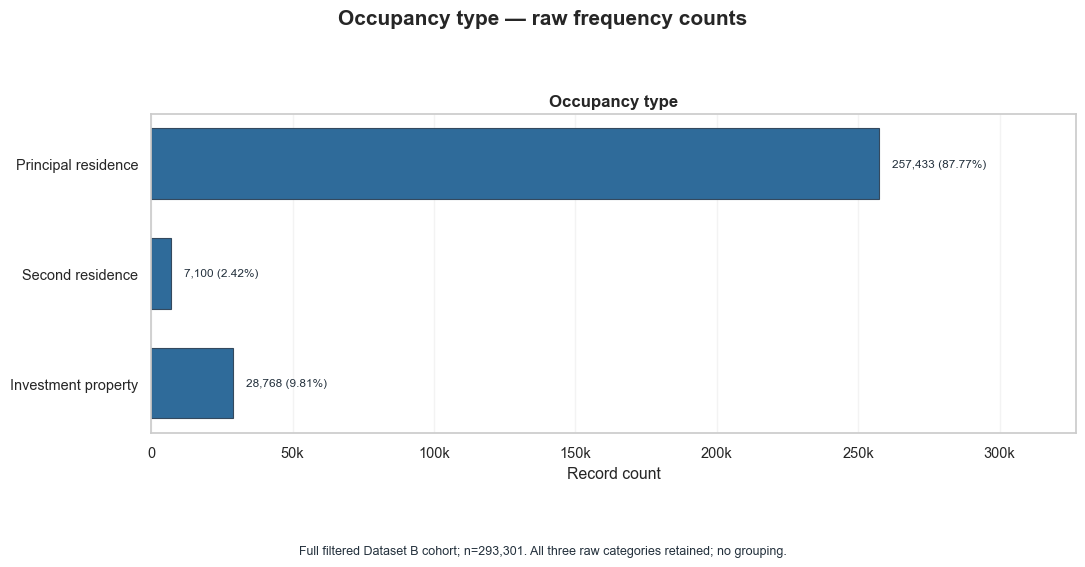

In [28]:
eda_task_05_occupancy_figure, occupancy_axis = plt.subplots(
    1, 1, figsize=(11, 5.2)
)
eda_task_05_occupancy_plot_data, _ = (
    eda_task_05_plot_frequency_axis(
        occupancy_axis,
        "occupancy_type",
        "Occupancy type",
    )
)
eda_task_05_occupancy_figure.suptitle(
    "Occupancy type — raw frequency counts",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
eda_task_05_occupancy_figure.text(
    0.5,
    -0.01,
    (
        f"Full filtered Dataset B cohort; n={EXPECTED_DATASET_B_ROWS:,}. "
        "All three raw categories retained; no grouping."
    ),
    ha="center",
    va="top",
    fontsize=9,
    color=EDA_TASK_05_COLORS["text"],
)
eda_task_05_occupancy_figure.tight_layout(rect=(0, 0.08, 1, 0.96))
plt.show()


**Figure 8 — Occupancy-type frequencies.** Population: full filtered Dataset B cohort, `n = 293,301`. Feature version: `temporary_training_lock_v0_2`. Statistic: raw frequency count and cohort share. Special states: none in the agreed raw domain; all three categories are retained without grouping. View: full categorical range. These are descriptive frequencies; any association reported in the notebook is not feature importance or causal evidence.


### 21. Task 05 acceptance gate


In [29]:
pd.testing.assert_frame_equal(
    eda_numeric_view,
    eda_task_05_numeric_before,
)
pd.testing.assert_frame_equal(
    eda_numeric_status_view,
    eda_task_05_status_before,
)
pd.testing.assert_frame_equal(
    eda_categorical_view,
    eda_task_05_categorical_before,
)

expected_category_counts = {
    feature: len(EDA_TASK_05_CATEGORY_ORDER[feature])
    for feature in EDA_TASK_05_FEATURES
}
observed_category_counts = (
    eda_task_05_frequency.groupby("feature")["raw_code"]
    .nunique()
    .to_dict()
)
assert observed_category_counts == expected_category_counts

for feature in EDA_TASK_05_FEATURES:
    feature_data = eda_task_05_frequency.loc[
        eda_task_05_frequency["feature"].eq(feature)
    ]
    assert int(feature_data["n"].sum()) == EXPECTED_DATASET_B_ROWS
    assert tuple(feature_data.sort_values("display_order")["raw_code"]) == (
        EDA_TASK_05_CATEGORY_ORDER[feature]
    )

assert len(eda_task_05_transaction_figure.axes) == 3
assert len(eda_task_05_product_figure.axes) == 2
assert len(eda_task_05_occupancy_figure.axes) == 1
for axis in transaction_axes:
    assert axis.patches[-1].get_hatch() == "///"
    assert all(
        patch.get_hatch() in (None, "")
        for patch in axis.patches[:-1]
    )

assert eda_forbidden_figure_columns.isdisjoint(
    EDA_TASK_05_FEATURES
)
for forbidden_table in (
    "quality_4_1",
    "quality_4_2",
    "quality_4_6",
    "decision_4_1",
    "decision_4_2",
    "decision_4_6",
    "validation_4_1",
    "validation_4_2",
    "validation_4_6",
):
    assert forbidden_table not in globals()

eda_task_05_summary = pd.Series(
    {
        "dataset_b_rows": EXPECTED_DATASET_B_ROWS,
        "categorical_features_plotted": len(EDA_TASK_05_FEATURES),
        "research_figures": 3,
        "bar_source": "raw frequency counts only",
        "rare_categories_grouped": False,
        "special_state_hatched": True,
        "quality_or_decision_tables_recreated": False,
        "task_02_views_unchanged": True,
        "target_used": False,
        "split_artifact_used": False,
        "model_preprocessing_used": False,
        "task_06_caption_cells_created": False,
    },
    name="Task 05 acceptance summary",
)

print("[DATA QUALITY] Task 05 frequency reconciliation")
for feature in EDA_TASK_05_FEATURES:
    feature_data = eda_task_05_frequency.loc[
        eda_task_05_frequency["feature"].eq(feature)
    ]
    special_n = int(
        feature_data.loc[feature_data["is_special"], "n"].sum()
    )
    print(
        f"[PASS] {feature}: categories={len(feature_data)}; "
        f"sum_n={int(feature_data['n'].sum()):,}; "
        f"special_n={special_n:,}"
    )
print("[DATA QUALITY] Task 05 acceptance summary")
print(eda_task_05_summary.to_string())
print("[PASS] Three categorical research figures were rendered from frequency counts only.")
print("[PASS] All raw categories are retained; no rare-category grouping was applied.")
print("[PASS] Exempt states use both distinct color and hatch in transaction figures.")
print("[PASS] No quality/decision/validation tables from notebook 04 were recreated.")
print("[PASS] Task 02 views are unchanged; no target, split or model preprocessing was used.")


[DATA QUALITY] Task 05 frequency reconciliation
[PASS] reverse_mortgage: categories=3; sum_n=293,301; special_n=8,636
[PASS] open-end_line_of_credit: categories=3; sum_n=293,301; special_n=8,322
[PASS] business_or_commercial_purpose: categories=3; sum_n=293,301; special_n=8,621
[PASS] loan_type: categories=4; sum_n=293,301; special_n=0
[PASS] loan_purpose: categories=6; sum_n=293,301; special_n=0
[PASS] occupancy_type: categories=3; sum_n=293,301; special_n=0
[DATA QUALITY] Task 05 acceptance summary
dataset_b_rows                                             293301
categorical_features_plotted                                    6
research_figures                                                3
bar_source                              raw frequency counts only
rare_categories_grouped                                     False
special_state_hatched                                        True
quality_or_decision_tables_recreated                        False
task_02_views_unchanged         

## Task 05 stop point

Task 05 dừng sau ba categorical frequency figures và acceptance gate. Không tạo thêm categorical plots ngoài phạm vi ưu tiên, không gộp category, không chạy target-conditioned hoặc protected-group comparisons. Caption chuẩn hóa và figure-supporting tables vẫn dành cho Task 06.


## Task 06 — Research captions and figure-supporting data

Captions above document population, feature version, statistic, special-state handling and view scope for every research figure. The tables below are limited to data needed to support those figures; they do not recreate notebook 04 screening, quality, validation, decision or feature-registry outputs.


In [30]:
eda_task_06_required = {
    "eda_feature_contract",
    "eda_association_pairs",
    "eda_task_02_numeric_quality",
    "eda_task_04_window_summary",
    "eda_task_05_frequency",
    "eda_numeric_view",
    "eda_numeric_status_view",
    "eda_categorical_view",
    "EXPECTED_DATASET_B_ROWS",
}
eda_task_06_missing = sorted(
    name
    for name in eda_task_06_required
    if name not in globals()
)
assert not eda_task_06_missing, (
    "Run Tasks 01–05 first. Missing variables: "
    f"{eda_task_06_missing}"
)

EDA_TASK_06_FEATURE_VERSION = eda_feature_contract[
    "feature_version"
]
assert EDA_TASK_06_FEATURE_VERSION == "temporary_training_lock_v0_2"

eda_task_06_numeric_before = eda_numeric_view.copy(deep=True)
eda_task_06_status_before = eda_numeric_status_view.copy(deep=True)
eda_task_06_categorical_before = eda_categorical_view.copy(deep=True)

print("[PASS] Task 06 consumes only executed Task 01–05 figure data.")
print(f"[PASS] Caption feature version: {EDA_TASK_06_FEATURE_VERSION}.")
print("[PASS] Notebook 04 screening/quality/decision tables remain outside Task 06.")


[PASS] Task 06 consumes only executed Task 01–05 figure data.
[PASS] Caption feature version: temporary_training_lock_v0_2.
[PASS] Notebook 04 screening/quality/decision tables remain outside Task 06.


### 22. Figure-supporting association data

The table is intentionally bounded to the 12 strongest unique pairs in the heatmap. `association_value` uses the same magnitude shown in Figure 1; `pairwise_n` reports the actual available denominator.


In [31]:
eda_task_06_association_support = (
    eda_association_pairs
    .sort_values(
        ["association_strength", "left", "right"],
        ascending=[False, True, True],
    )
    .head(12)
    .loc[
        :,
        [
            "left",
            "right",
            "method",
            "association_strength",
            "n",
        ],
    ]
    .rename(
        columns={
            "left": "feature_1",
            "right": "feature_2",
            "method": "statistic",
            "association_strength": "association_value",
            "n": "pairwise_n",
        }
    )
    .reset_index(drop=True)
)
eda_task_06_association_support["association_value"] = (
    eda_task_06_association_support["association_value"].round(4)
)

eda_task_06_association_support


,feature_1,feature_2,statistic,association_value,pairwise_n
0,business_or_commercial_purpose,debt_to_income_ratio,bias_corrected_cramers_v,0.8493,293301
1,open-end_line_of_credit,debt_to_income_ratio,bias_corrected_cramers_v,0.7226,293301
2,reverse_mortgage,debt_to_income_ratio,bias_corrected_cramers_v,0.7173,293301
3,reverse_mortgage,business_or_commercial_purpose,bias_corrected_cramers_v,0.7060,293301
4,open-end_line_of_credit,business_or_commercial_purpose,bias_corrected_cramers_v,0.7037,293301
5,reverse_mortgage,open-end_line_of_credit,bias_corrected_cramers_v,0.6950,293301
6,loan_purpose,lien_status,bias_corrected_cramers_v,0.6779,293301
7,business_or_commercial_purpose,occupancy_type,bias_corrected_cramers_v,0.6208,293301
8,lien_status,open-end_line_of_credit,bias_corrected_cramers_v,0.6109,293301
9,income,loan_amount,abs_spearman,0.5039,272723


### 23. Figure-supporting numeric coverage and central windows

Counts reconcile the numeric figure population, explicit special states and observations outside each central display window. These are figure-supporting counts, not distribution or feature-screening tables.


In [32]:
numeric_counts = (
    eda_task_02_numeric_quality
    .set_index("feature")
)
numeric_support_rows = []

for feature, window_row in eda_task_04_window_summary.iterrows():
    counts = numeric_counts.loc[feature]
    numeric_support_rows.append(
        {
            "feature": feature,
            "observed_numeric_n": int(counts["numeric_n"]),
            "special_n": int(counts["special_n"]),
            "NA_n": int(counts["NA_n"]),
            "Exempt_n": int(counts["Exempt_n"]),
            "central_window": (
                f"{eda_task_04_format_number(window_row['window_lower'])} "
                f"to {eda_task_04_format_number(window_row['window_upper'])}"
            ),
            "outside_window_n": int(window_row["outside_n"]),
            "outside_window_pct": round(
                float(window_row["outside_pct"]), 2
            ),
        }
    )

eda_task_06_numeric_support = pd.DataFrame(
    numeric_support_rows
)

eda_task_06_numeric_support


,feature,observed_numeric_n,special_n,NA_n,Exempt_n,central_window,outside_window_n,outside_window_pct
0,income,272723,20578,20578,0,"0 to 1,242",3087,1.13
1,loan_amount,293301,0,0,0,"15,000 to 2,435,000",3685,1.26
2,loan_to_value_ratio,274681,18620,9978,8642,0 to 250,192,0.07
3,loan_term,274648,18653,10360,8293,12 to 360,2780,1.01


### 24. Figure-supporting categorical frequencies

This table contains the exact 22 bars shown in Figures 6–8. It preserves raw codes, all rare categories and explicit special-state status.


In [33]:
eda_task_06_categorical_support = (
    eda_task_05_frequency
    .assign(
        state=lambda frame: np.where(
            frame["is_special"],
            "special",
            "informative",
        ),
        share_pct=lambda frame: frame["share_pct"].round(2),
    )
    .loc[
        :,
        [
            "feature",
            "raw_code",
            "label",
            "state",
            "n",
            "share_pct",
        ],
    ]
    .reset_index(drop=True)
)

eda_task_06_categorical_support


,feature,raw_code,label,state,n,share_pct
0,reverse_mortgage,1,Reverse mortgage,informative,786,0.27
1,reverse_mortgage,2,Not reverse mortgage,informative,283879,96.79
2,reverse_mortgage,1111,Exempt (1111),special,8636,2.94
3,open-end_line_of_credit,1,Open-end credit,informative,81148,27.67
4,open-end_line_of_credit,2,Not open-end credit,informative,203831,69.50
5,open-end_line_of_credit,1111,Exempt (1111),special,8322,2.84
6,business_or_commercial_purpose,1,Business/commercial,informative,25039,8.54
7,business_or_commercial_purpose,2,Not business/commercial,informative,259641,88.52
8,business_or_commercial_purpose,1111,Exempt (1111),special,8621,2.94
9,loan_type,1,Conventional,informative,265629,90.57


### 25. Task 06 acceptance gate


In [34]:
pd.testing.assert_frame_equal(
    eda_numeric_view,
    eda_task_06_numeric_before,
)
pd.testing.assert_frame_equal(
    eda_numeric_status_view,
    eda_task_06_status_before,
)
pd.testing.assert_frame_equal(
    eda_categorical_view,
    eda_task_06_categorical_before,
)

assert len(eda_task_06_association_support) == 12
assert eda_task_06_association_support[
    "association_value"
].between(0, 1).all()
assert eda_task_06_association_support["pairwise_n"].between(
    1,
    EXPECTED_DATASET_B_ROWS,
).all()

assert len(eda_task_06_numeric_support) == 4
assert (
    eda_task_06_numeric_support["observed_numeric_n"]
    + eda_task_06_numeric_support["special_n"]
).eq(EXPECTED_DATASET_B_ROWS).all()
assert eda_task_06_numeric_support["outside_window_n"].gt(0).all()

assert len(eda_task_06_categorical_support) == 22
categorical_totals = (
    eda_task_06_categorical_support
    .groupby("feature", sort=False)["n"]
    .sum()
)
assert categorical_totals.eq(EXPECTED_DATASET_B_ROWS).all()
assert set(eda_task_06_categorical_support["state"]) == {
    "informative",
    "special",
}

for forbidden_table in (
    "quality_4_1",
    "quality_4_2",
    "quality_4_3",
    "quality_4_4",
    "quality_4_5",
    "quality_4_6",
    "decision_4_1",
    "decision_4_2",
    "decision_4_3",
    "decision_4_4",
    "decision_4_5",
    "decision_4_6",
    "validation_4_1",
    "validation_4_2",
    "validation_4_3",
    "validation_4_4",
    "validation_4_5",
    "validation_4_6",
):
    assert forbidden_table not in globals()

eda_task_06_summary = pd.Series(
    {
        "dataset_b_rows": EXPECTED_DATASET_B_ROWS,
        "feature_version": EDA_TASK_06_FEATURE_VERSION,
        "figure_captions": 8,
        "association_support_rows": len(
            eda_task_06_association_support
        ),
        "numeric_support_rows": len(
            eda_task_06_numeric_support
        ),
        "categorical_support_rows": len(
            eda_task_06_categorical_support
        ),
        "notebook_04_tables_recreated": False,
        "task_02_views_unchanged": True,
        "target_used": False,
        "split_artifact_used": False,
        "model_preprocessing_used": False,
    },
    name="Task 06 acceptance summary",
)

print("[DATA QUALITY] Task 06 acceptance summary")
print(eda_task_06_summary.to_string())
print("[PASS] Eight research figures have scoped captions.")
print("[PASS] Association support includes value, method and pairwise n.")
print("[PASS] Numeric support reconciles observed, special and central-window counts.")
print("[PASS] Categorical support contains exactly the 22 displayed bars.")
print("[PASS] No notebook 04 quality/decision/validation table was recreated.")
print("[PASS] Task 02 views are unchanged; no target, split or model preprocessing was used.")


[DATA QUALITY] Task 06 acceptance summary
dataset_b_rows                                        293301
feature_version                 temporary_training_lock_v0_2
figure_captions                                            8
association_support_rows                                  12
numeric_support_rows                                       4
categorical_support_rows                                  22
notebook_04_tables_recreated                           False
task_02_views_unchanged                                 True
target_used                                            False
split_artifact_used                                    False
model_preprocessing_used                               False
[PASS] Eight research figures have scoped captions.
[PASS] Association support includes value, method and pairwise n.
[PASS] Numeric support reconciles observed, special and central-window counts.
[PASS] Categorical support contains exactly the 22 displayed bars.
[PASS] No notebook 04 q

## Task 06 stop point

Task 06 dừng sau tám research captions, ba bounded figure-supporting tables và acceptance gate. Không tạo feature registry, screening/decision tables, model-conditioned results hoặc protected-group comparisons.
